Задача: построить модель многоклассовой классификации, которая по цифровому поведению пользователя определеяет его возрастную категорию.

## Содержимое проекта

- [1. Постановка задачи машинного обучения](#section1)
- [2. Подготовка среды и библиотек](#section2)
 - [2.1. Подключение и настройка библиотек](#section21)
 - [2.2. Загрузка датасета](#section22)
- [3. Подготовка данных](#section3)
- [4. Исследовательский анализ данных (EDA)](#section4)
 - [4.1. Описание данных](#section41)
 - [4.2. Описание целевой переменной](#section42)
 - [4.3. Наличие пропусков в данных](#section43)
 - [4.4. Дубликаты](#section44)
 - [4.5. Анализ категориальных признаков](#section45)
 - [4.6. Анализ числовых признаков и выбросов](#section46)
 - [4.7. Вывод](#section47)
- [5. Предобработка данных](#section5)
- [6. Обучение и оценка базовой модели](#section6)
- [7. Создание и отбор признаков](#section7)
- [8. Подбор гиперпараметров моделей](#section8)
- [9. Финальная модель](#section9)
- [10. Подготовка артефактов модели для внедрения](#section10)
- [11. Выводы о результатах работы](#section11)

<h3 id="section1">1. Постановка задачи машинного обучения</h3>

Необходимо разработать модель машинного обучения для предсказания возрастной катоегории пользователей рекламной сети по данным о его поведении в интернете: истории посещения сайтов, категориям посещаемых ресурсов, частоте и времени активности. Целевой переменной является возрастная категория пользователя (0 - младше 18 лет, 1 - 18-25 лет, 2 - 26-40 лет, 3 - 41-55 лет, 4 - 56+ лет), поэтому задача относится к многоклассовой классификации.

Для оценки качества модели будет использоваться основная метрика - F1-мера с макро-усреднением (F1-macro), которая позволяет одинаково учитывать качество классификации всех возрастных категорий, в том числе редких классов. Дополнительно будут использованы метрики precision и recall c макро-усреднением. Для итоговой оценки тестовая выборка составит 20% от всего датасета.

В рамках проекта будут исследованы и сравнены несколько моделей машинного обучениz - базовая Dummy-модель, логистическая регрессия и модели опорных векторов с различными ядрами. Для выбора лучшей модели будет применяться стратифицированная кросс-валидация и подбор гиперпараметров.

Итоговая модель должна достичь значения F1-macro не менее 0.75 как на кросс-валидации обучающей выборки, так и на тестовой выборке. При выполнении этого условия модель может быть рекомендована для внедрения в рекламную систему и использоваться для более точного возрастного таргетинга рекламы.

<h3 id="section2">2. Подготовка среды и библиотек</h3>

<h3 id="section21">2.1. Подключение и настройка библиотек</h3>

In [1]:
%pip install -q \
pandas==2.2.3 \
numpy==1.26.4 \
scipy==1.13.1 \
matplotlib==3.9.4 \
scikit-learn==1.6.1 \
phik==0.12.4 \
seaborn==0.13.2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (log_loss,
                             average_precision_score,
                             precision_recall_curve,
                             precision_score,
                             recall_score,
                             f1_score,
                             brier_score_loss)

from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SequentialFeatureSelector as SFS
from sklearn.feature_selection import (RFE,
                                       SelectFromModel,
                                       VarianceThreshold,
                                       RFECV,
                                       SelectKBest,
                                       mutual_info_classif)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.calibration import CalibratedClassifierCV,calibration_curve, CalibrationDisplay
from phik import phik_matrix
from scipy.special import expit
from sklearn.frozen import FrozenEstimator
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
from sklearn.metrics import classification_report

In [3]:
import warnings
warnings.filterwarnings("ignore")

In [4]:
# настройки отображения
pd.set_option('display.float_format', '{:.4f}'.format)

In [5]:
# фиксируем констанстанту для воспроизводимости
RANDOM_STATE = 42

<h3 id="section22">2.2. Загрузка датасета</h3>

Начнем с выгрузки данных из файлов `ds_s13_users.csv `, `ds_s13_visits.csv`, `ads_activity.csv`, `surf_depth.csv`, `primary_device.csv` и `cloud_usage.csv` в соответствующие переменные.

In [6]:
try:
    df_users = pd.read_csv ('ds_s13_users.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')
except:
    df_users = pd.read_csv ('https://code.s3.yandex.net/datasets/ds_s13_users.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')

In [7]:
try:
    df_visits = pd.read_csv ('ds_s13_visits.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')
except:
    df_visits = pd.read_csv ('https://code.s3.yandex.net/datasets/ds_s13_visits.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')

In [8]:
try:
    df_activity = pd.read_csv ('ads_activity.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')
except:
    df_activity = pd.read_csv ('https://code.s3.yandex.net/datasets/ads_activity.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')

In [9]:
try:
    df_surf = pd.read_csv ('surf_depth.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')
except:
    df_surf = pd.read_csv ('https://code.s3.yandex.net/datasets/surf_depth.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')

In [10]:
try:
    df_device = pd.read_csv ('primary_device.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')
except:
    df_device = pd.read_csv ('https://code.s3.yandex.net/datasets/primary_device.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')

In [11]:
try:
    df_usage = pd.read_csv ('cloud_usage.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')
except:
    df_usage = pd.read_csv ('https://code.s3.yandex.net/datasets/cloud_usage.csv',
                      sep = ',', decimal = '.', skiprows = 0, on_bad_lines = 'error')

Познакомимся с данными:

In [12]:
df_users.info()
df_users.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5913 entries, 0 to 5912
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   user_id       5913 non-null   object
 1   age_category  5913 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 92.5+ KB


,user_id,age_category
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2
2,678b-614cd47d854b9d591db2-000b2e50,0
3,4ac0-dad169100b4a29b20818-b26ae7c5,4
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0


In [13]:
df_visits.info()
df_visits.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1065745 entries, 0 to 1065744
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype 
---  ------            --------------    ----- 
 0   date              1065745 non-null  object
 1   daytime           1065745 non-null  object
 2   session_id        1065745 non-null  object
 3   user_id           1065745 non-null  object
 4   website_category  1065745 non-null  object
dtypes: object(5)
memory usage: 40.7+ MB


,date,daytime,session_id,user_id,website_category
0,2025-11-01,вечер,066e4e02-8c1f-45eb-a50f-178659abe698,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 17
1,2025-11-01,вечер,0bce1749-3376-439c-9a22-f8ffbba00e9a,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 19
2,2025-11-01,вечер,3445d8c4-221d-4d88-bb6a-a2939fe3c610,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 18
3,2025-11-01,вечер,3bf97286-1d91-4aaa-af4a-ed58eceb8cd2,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 20
4,2025-11-01,вечер,40e22712-3cad-410d-a9f0-13bd8f6911c0,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 05


In [14]:
df_activity.info()
df_activity.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5826 entries, 0 to 5825
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   user_id       5826 non-null   object
 1   ads_activity  5826 non-null   object
dtypes: object(2)
memory usage: 91.2+ KB


,user_id,ads_activity
0,e318-d8e69c86b543a5fb927c-c36fb6e6,очень часто
1,35cd-a972339dec534f49332c-a8b6d383,редко
2,f7e6-3b29cf9cb7ed4bb00d8f-81534360,очень редко
3,5186-e25a37549e50f45b2b43-178eaabe,умеренно
4,febd-077f277466253ee04ef6-42656680,умеренно


In [15]:
df_surf.info()
df_surf.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5715 entries, 0 to 5714
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     5715 non-null   object
 1   surf_depth  5715 non-null   object
dtypes: object(2)
memory usage: 89.4+ KB


,user_id,surf_depth
0,f238-0c4c1e787cce311541b7-736925a0,поверхностно
1,9030-1b562ad80182b6dc27f1-ce811740,глубоко
2,22e0-7c6cadcc45e246b8688d-c43c9b23,поверхностно
3,9d7f-a19f10756378940a49b5-5d03e1ef,поверхностно
4,4233-bb5ae4b09827e5497094-1a4956af,глубоко


In [16]:
df_device.info()
df_device.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5669 entries, 0 to 5668
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   user_id         5669 non-null   object
 1   primary_device  5669 non-null   object
dtypes: object(2)
memory usage: 88.7+ KB


,user_id,primary_device
0,d602-ec060db7597a6b8cd4e7-aa625896,смартфон
1,9204-9558455be649d4e77945-b5e25d62,ПК
2,5eea-22babd6a9474b43b9d0b-a39a4cf2,ноутбук
3,c142-0296948e8d08e417de10-2da9523c,смартфон
4,abec-bb4092da51eb2233a928-e44ba074,ПК


In [17]:
df_usage.info()
df_usage.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5680 entries, 0 to 5679
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      5680 non-null   object
 1   cloud_usage  5680 non-null   bool  
dtypes: bool(1), object(1)
memory usage: 50.0+ KB


,user_id,cloud_usage
0,a1e4-91c8a52eb855595e653f-298ce305,False
1,db9a-7b8e9e94448b7fcb19b6-4edca15f,False
2,0d55-9ad768879e9b08ca7ff9-843f76c7,True
3,4baa-43285d10a6d3cc969f2a-b21881d1,False
4,b8cd-cbb2411db005115ca64d-32700c62,False


После загрузки данных получены следующие таблицы:

- `users` — 5 913 строк, 2 столбца: идентификатор пользователя и целевая переменная `age_category`;
- `visits` — 1 065 745 строк, 5 столбцов: данные о посещениях сайтов, включая дату, время суток, сессию, пользователя и категорию сайта;
- `activity` — 5 826 строк, 2 столбца: частота взаимодействия пользователя с рекламой;
- `surf_depth` — 5 715 строк, 2 столбца: глубина просмотра сайтов;
- `device` — 5 669 строк, 2 столбца: основное устройство пользователя;
- `usage` — 5 680 строк, 2 столбца: факт использования облачных сервисов.

Во всех таблицах `user_id` используется для связи данных между таблицами.

Данные имеют разную структуру: таблица `visits` содержит событийные данные, где одному пользователю соответствует множество записей, тогда как остальные таблицы содержат агрегированные характеристики пользователей. Поэтому на следующем этапе необходимо объединить таблицы по `user_id`, предварительно агрегировав данные из `visits` и сформировав на их основе дополнительные признаки. Полученная единая таблица будет использоваться  для дальнейшего обучения модели.

<h3 id="section3">3. Подготовка данных</h3>

###  Users

Перед этапом исследовательского анализа данных, необходимо изучить имеющиеся таблицы и объединить их в единый датафрейм. Начнем с изучения датафрейма `df_users`. Выведем размер, кол-во уникальных пользователей и посмотрим, есть ли дубликаты.

In [18]:
# вывод статистик для таблиц
def stat(df):
    display(df.describe())
    print('Размер датафрейма:', df.shape)
    print('Уникальных пользователей:', df['user_id'].nunique())
    print('Кол-во дубликатов:', df.duplicated().sum())
    print ('\n')
    print('Кол-во пропусков:')
    print (df.isnull().sum())
    print('\n')
    print('Типы данных:')
    print (df.dtypes)

In [19]:
stat(df_users)

,age_category
count,5913.0000
mean,2.4416
std,1.3803
min,0.0000
25%,2.0000
50%,3.0000
75%,4.0000
max,4.0000


Размер датафрейма: (5913, 2)
Уникальных пользователей: 5826
Кол-во дубликатов: 87


Кол-во пропусков:
user_id         0
age_category    0
dtype: int64


Типы данных:
user_id         object
age_category     int64
dtype: object


Из результатов видно, что пропусков в тарегете нет, но есть полные дубликаты. Выведем их, чтобы проверить.

In [20]:
df_users[df_users.duplicated(keep = False)].sort_values(by = 'user_id' ).head(10)

,user_id,age_category
5218,0217-17b504a06ce90f0c0441-ce7e7aa2,0
2351,0217-17b504a06ce90f0c0441-ce7e7aa2,0
1554,036b-a85efa206bd9e9d86fa8-20152d7f,4
317,036b-a85efa206bd9e9d86fa8-20152d7f,4
1331,041d-48afbfadf1b0387c77a8-14776807,2
577,041d-48afbfadf1b0387c77a8-14776807,2
2394,05dc-feaa264cf69411853e5f-fdaf96bd,3
3547,05dc-feaa264cf69411853e5f-fdaf96bd,3
1074,0aa3-ba02805bbfb18af69a07-6883b173,0
1714,0aa3-ba02805bbfb18af69a07-6883b173,0


Убедились, что это действительно дубликаты, поэтому теперь необходимо их удалить. Вероятно, это техническая ошибка. Удаление дубликатов необходимо до разделения данных, иначе метрика может быть завышена из-за попадания одинаковых объектов в обучающую и тестовую выборки.

In [21]:
df_users = df_users.drop_duplicates().reset_index (drop = True)

Проверим результат удаления:

In [22]:
print('Размер датафрейма:', df_users.shape)
print('Уникальных пользователей:', df_users['user_id'].nunique())
print('Кол-во дубликатов:', df_users.duplicated().sum())

Размер датафрейма: (5826, 2)
Уникальных пользователей: 5826
Кол-во дубликатов: 0


В таблице `df_users` обнаружено 87 полных дубликатов. Пропущенных значений нет. После удаления дубликатов осталось 5 826 уникальных пользователей, количество дубликатов стало равно 0. Индексы после удаления были сброшены для корректной нумерации строк.

### Visits

In [23]:
stat (df_visits)

,date,daytime,session_id,user_id,website_category
count,1065745,1065745,1065745,1065745,1065745
unique,14,4,1049995,5826,20
top,2025-11-13,день,d428ace6-8e86-4127-b653-c8ae3c1d0443,5ff2-0a5aa967e353041283b9-ff7929cc,Category 03
freq,76599,389052,2,853,70260


Размер датафрейма: (1065745, 5)
Уникальных пользователей: 5826
Кол-во дубликатов: 15750


Кол-во пропусков:
date                0
daytime             0
session_id          0
user_id             0
website_category    0
dtype: int64


Типы данных:
date                object
daytime             object
session_id          object
user_id             object
website_category    object
dtype: object


Посмотрим интервал, за который представлены логи:

In [24]:
print (df_visits['date'].min())
print (df_visits['date'].max())

2025-11-01
2025-11-14


Выведем дубликаты:

In [25]:
df_visits[df_visits.duplicated(keep = False)].sort_values(by = 'session_id').head(10)

,date,daytime,session_id,user_id,website_category
176851,2025-11-03,вечер,00035998-7126-4e05-afee-0aa9f58cd6cc,e433-85a5acdd077d54acdc1f-39a9c95c,Category 18
176852,2025-11-03,вечер,00035998-7126-4e05-afee-0aa9f58cd6cc,e433-85a5acdd077d54acdc1f-39a9c95c,Category 18
131250,2025-11-02,ночь,0004a16a-cc16-49e4-a29d-b3c98477c80f,0246-e19c2db073cec9ecf2cd-40e5f05e,Category 03
131249,2025-11-02,ночь,0004a16a-cc16-49e4-a29d-b3c98477c80f,0246-e19c2db073cec9ecf2cd-40e5f05e,Category 03
29244,2025-11-01,день,0009b75d-aa33-4f9e-b317-60238b086a66,12e2-5837e0d4ae79cf526176-262455e5,Category 16
29243,2025-11-01,день,0009b75d-aa33-4f9e-b317-60238b086a66,12e2-5837e0d4ae79cf526176-262455e5,Category 16
896217,2025-11-12,ночь,002008b0-499f-495d-878d-754f84e5d3f3,9b87-39dc13fad33d528ac7c1-7436b57c,Category 02
896218,2025-11-12,ночь,002008b0-499f-495d-878d-754f84e5d3f3,9b87-39dc13fad33d528ac7c1-7436b57c,Category 02
305378,2025-11-05,вечер,0021b99b-9b48-4789-8008-86fad20a1031,041d-48afbfadf1b0387c77a8-14776807,Category 05
305377,2025-11-05,вечер,0021b99b-9b48-4789-8008-86fad20a1031,041d-48afbfadf1b0387c77a8-14776807,Category 05


Вероятно, данные задвоились из-за технической ошибки. Удалим дубликаты.

In [26]:
df_visits = df_visits.drop_duplicates()

Теперь рассмотрим варианты агрегации признаков по `user_id` из столбцов - `date`, `daytime`,`session_id`, `website_category`.

Из столбца `session_id` выделим следующие признаки:
- `avg_session_per_day` - среднее количество сессий в день;
- `visits_per_session` —  среднее число записей/посещений в одной сессии;
- `max_visits_per_session` - самая длинная сессия;
- `min_visits_per_session` - самая короткая сессия.

Из столбца `daytime`:
- `daytime_share` - какая доля интернет-активности приходится на разное время суток;
- `peak_daytime` - самое активное время суток у пользователя.

Из столбца `website_category`:
- `category_share` - доля активности пользователя в каждой категории;
- `category_unique` - сколько разных категорий интересует пользователя.

Из столбца `date`:
- `weekday_share` - доля активности по дням недели.

In [27]:
# количество действий в каждой сессии
session_stats = df_visits.groupby(['user_id', 'session_id']).size().reset_index (name = 'visits_in_session')
session_stats['visits_in_session'].describe()

count   1049995.0000
mean          1.0000
std           0.0000
min           1.0000
25%           1.0000
50%           1.0000
75%           1.0000
max           1.0000
Name: visits_in_session, dtype: float64

Оказалось, что каждая сессия встречается ровно один раз - поэтому признаки `visits_per_session`, `max_visits_per_session` и `min_visits_per_session` будут бесполезны. Оставим только среднее количество сессий в день.

In [28]:
# количество сессий в день
sessions_per_day=df_visits.groupby(['user_id','date'])['session_id'].count().reset_index(name = 'sessions_per_day')
# среднее значение
avg_sessions_per_day = sessions_per_day.groupby('user_id')['sessions_per_day'].mean().reset_index(
                                                                                    name = 'avg_sessions_per_day')

In [29]:
# количество посещений пользователя в каждое время суток
daytime_count = df_visits.groupby(['user_id', 'daytime']).size().reset_index(name = 'daytime_count')
daytime_pivot = daytime_count.pivot (index = 'user_id', columns = 'daytime', values = 'daytime_count')
daytime_share = daytime_pivot.div(daytime_pivot.sum(axis = 1), axis = 0).fillna(0)
# переименовываем столбцы
daytime_share.columns = [f'daytime_share_{col}' for col in daytime_share.columns]
#удалим один из стоблцов (ниже пояснение)
daytime_share = daytime_share.iloc[:, :-1]
# наиболее активное время суток
peak_daytime = daytime_count.loc[daytime_count.groupby('user_id')['daytime_count'].idxmax()][[
    'user_id', 'daytime']].rename(columns={'daytime': 'peak_daytime'})

Один из признаков `daytime_share` удалён, поскольку признаки являются линейно зависимыми: сумма долей посещений пользователя по всем периодам суток равна 1. Оставление всех столбцов приводит к мультиколлинеарности и избыточности признакового пространства, поэтому один из них исключён.

In [30]:
# количество посещений каждой категории
category_count = df_visits.groupby(['user_id', 
                                            'website_category']).size().reset_index(name = 'category_count')
# формируем таблицу и NaN заполняем нулями
category_count_pivot = category_count.pivot (index = 'user_id',
                                                             columns = 'website_category',
                                                            values = 'category_count').fillna(0)
# доли активности пользователя в каждой категории
category_share = category_count_pivot.div(category_count_pivot.sum(axis=1), axis = 0)
category_share.columns = [f'category_share_{col}' for col in category_share.columns]
# удаляем один из признаков из-за избыточности
category_share = category_share.iloc[:, :-1]
# количество уникальных категорий, которые интересуют пользователя
category_unique = (df_visits.groupby('user_id')['website_category'].nunique().reset_index(name = 'category_unique'))

In [31]:
df_visits['date'] = pd.to_datetime (df_visits['date'])
df_visits['dayofweek'] = df_visits['date'].dt.dayofweek
# группируем по дням недели
weekday_count = df_visits.groupby(['user_id', 'dayofweek']).size().reset_index (name = 'weekday_count')

weekday_pivot = weekday_count.pivot(index = 'user_id',
                                   columns = 'dayofweek',
                                   values = 'weekday_count').fillna(0)
#доли активности по дням недели
weekday_share = weekday_pivot.div(weekday_pivot.sum(axis=1), axis=0)
weekday_share.columns = [f'weekday_share_{col}' for col in weekday_share.columns]
#удаляем один из признаков из-за избыточности
weekday_share = weekday_share.iloc[:, :-1]

Теперь объединим все агрегированные признаки в единую таблицу.

In [32]:
visits_features = (avg_sessions_per_day.merge (daytime_share, on = 'user_id',how = 'left')
                   .merge(peak_daytime, on = 'user_id', how = 'left')
                   .merge (category_share, on = 'user_id', how = 'left')
                   .merge (category_unique, on = 'user_id', how = 'left')
                   .merge (weekday_share, on = 'user_id', how = 'left'))

Выведем итоговую таблицу `visits_features`:

In [33]:
visits_features.head(5)

,user_id,avg_sessions_per_day,daytime_share_вечер,daytime_share_день,daytime_share_ночь,peak_daytime,category_share_Category 01,category_share_Category 02,category_share_Category 03,category_share_Category 04,...,category_share_Category 17,category_share_Category 18,category_share_Category 19,category_unique,weekday_share_0,weekday_share_1,weekday_share_2,weekday_share_3,weekday_share_4,weekday_share_5
0,0010-5cf8f6b38a7b6c70a021-009dbcda,39.0000,0.4139,0.3260,0.0952,вечер,0.0293,0.0000,0.0623,0.0421,...,0.0513,0.0788,0.0916,19,0.1630,0.1282,0.1355,0.1300,0.1575,0.1502
1,0013-4ae5f7d127b91a3fb0f8-ba59f141,13.2143,0.2757,0.3730,0.0865,день,0.0811,0.0595,0.0270,0.0378,...,0.0649,0.0865,0.0054,19,0.1514,0.1459,0.1730,0.1351,0.1568,0.1297
2,0014-d3032d60979a8d2b3077-f09bdce8,8.3571,0.3077,0.3846,0.0940,день,0.0085,0.0171,0.0342,0.0598,...,0.0769,0.0256,0.1026,19,0.1453,0.1709,0.1026,0.1282,0.1709,0.1709
3,001a-eee53e44f848608779b0-78704a67,20.5000,0.4146,0.3345,0.1080,вечер,0.0662,0.0453,0.0348,0.0767,...,0.0453,0.0732,0.0732,19,0.1045,0.1568,0.1533,0.1429,0.1463,0.1394
4,002c-40a064b12e1217e12207-a56eaf3b,35.0000,0.2959,0.3837,0.0694,день,0.0000,0.0531,0.0714,0.0612,...,0.0347,0.0122,0.0510,18,0.1673,0.1388,0.1571,0.1245,0.1510,0.1184


Выведем размер `visits_features`:

In [34]:
print('Размер датафрейма:', visits_features .shape)

Размер датафрейма: (5826, 32)


По итогам агрегации `df_visits` сформирован единый набор поведенческих признаков на уровне пользователя. Были рассчитаны среднее количество сессий в день, распределение активности по времени суток, наиболее активное время, доли посещений различных категорий сайтов, количество уникальных категорий и распределение активности по дням недели.

После объединения всех агрегированных признаков получена таблица `visits_features` размером 5 826 строк и 33 столбца — по одной строке на каждого уникального пользователя.

### Activity

In [35]:
stat (df_activity)

,user_id,ads_activity
count,5826,5826
unique,5593,5
top,168a-d84a1e43b19b278f770a-63214e42,умеренно
freq,2,1897


Размер датафрейма: (5826, 2)
Уникальных пользователей: 5593
Кол-во дубликатов: 233


Кол-во пропусков:
user_id         0
ads_activity    0
dtype: int64


Типы данных:
user_id         object
ads_activity    object
dtype: object


Снова видим дубликаты в данных. Вероятно, это систематическая ошибка, поэтому при подготовке отдельной функции для объединения таблиц в единый датафрейм включим обязательую проверку на дубликаты по всем таблицам.

Выведем дубликаты для проверки корректности и удалим их.

In [36]:
df_activity[df_activity.duplicated(keep=False)].sort_values(by = 'user_id').head()

,user_id,ads_activity
4306,0259-a9907d16efbe00c4e18a-ce0364c9,очень часто
5488,0259-a9907d16efbe00c4e18a-ce0364c9,очень часто
976,02d4-8707e8f46c6769731dd5-c268adff,очень редко
3481,02d4-8707e8f46c6769731dd5-c268adff,очень редко
4146,0501-ba75c2755d55061a096d-d0e8c7db,часто


In [37]:
df_activity = df_activity.drop_duplicates()

Проверим результат удаления:

In [38]:
print('Размер датафрейма:', df_activity.shape)
print('Уникальных пользователей:', df_activity['user_id'].nunique())
print('Кол-во дубликатов:', df_activity.duplicated().sum())

Размер датафрейма: (5593, 2)
Уникальных пользователей: 5593
Кол-во дубликатов: 0


В таблице `df_activity` обнаружено 233 полных дубликатов, которые были удалены. Пропущенных значений нет. После удаления дубликатов осталось 5 593 уникальных пользователей.

### Surf_depth

In [39]:
stat(df_surf)

,user_id,surf_depth
count,5715,5715
unique,5715,3
top,f238-0c4c1e787cce311541b7-736925a0,средне
freq,1,2435


Размер датафрейма: (5715, 2)
Уникальных пользователей: 5715
Кол-во дубликатов: 0


Кол-во пропусков:
user_id       0
surf_depth    0
dtype: int64


Типы данных:
user_id       object
surf_depth    object
dtype: object


В таблице нет дубликатов и пропусков, обработка данных не трубуется.

### Device

In [40]:
stat(df_device)

,user_id,primary_device
count,5669,5669
unique,5669,4
top,d602-ec060db7597a6b8cd4e7-aa625896,смартфон
freq,1,3083


Размер датафрейма: (5669, 2)
Уникальных пользователей: 5669
Кол-во дубликатов: 0


Кол-во пропусков:
user_id           0
primary_device    0
dtype: int64


Типы данных:
user_id           object
primary_device    object
dtype: object


В таблице нет дубликатов и пропусков, обработка данных не трубуется.

### Cloud_usage

In [41]:
stat(df_usage)

,user_id,cloud_usage
count,5680,5680
unique,5680,2
top,a1e4-91c8a52eb855595e653f-298ce305,True
freq,1,2951


Размер датафрейма: (5680, 2)
Уникальных пользователей: 5680
Кол-во дубликатов: 0


Кол-во пропусков:
user_id        0
cloud_usage    0
dtype: int64


Типы данных:
user_id        object
cloud_usage      bool
dtype: object


В таблице нет дубликатов и пропусков, обработка данных не трубуется.

Присоединим таблицы `visits_features`, `df_activity`, `df_surf`, `df_device`, `df_usage` к `df_users `.

In [42]:
df = (df_users.merge(visits_features, on = 'user_id',how = 'left')
      .merge (df_activity,on = 'user_id',how = 'left' )
      .merge (df_surf,on = 'user_id', how = 'left' )
      .merge (df_device, on = 'user_id', how = 'left' )
      .merge (df_usage,on = 'user_id',how = 'left' ))



In [43]:
df.head(5)

,user_id,age_category,avg_sessions_per_day,daytime_share_вечер,daytime_share_день,daytime_share_ночь,peak_daytime,category_share_Category 01,category_share_Category 02,category_share_Category 03,...,weekday_share_0,weekday_share_1,weekday_share_2,weekday_share_3,weekday_share_4,weekday_share_5,ads_activity,surf_depth,primary_device,cloud_usage
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4,13.3571,0.3369,0.3583,0.0749,день,0.0642,0.0374,0.0374,...,0.1497,0.1497,0.1176,0.1337,0.1497,0.1497,NaN,глубоко,смартфон,False
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2,10.0714,0.3901,0.3404,0.0922,вечер,0.0638,0.0426,0.0993,...,0.1418,0.1773,0.1348,0.1277,0.0993,0.1702,умеренно,средне,смартфон,False
2,678b-614cd47d854b9d591db2-000b2e50,0,7.1429,0.3800,0.2900,0.1300,вечер,0.0100,0.0700,0.0000,...,0.0900,0.1700,0.1500,0.2100,0.1100,0.1300,умеренно,средне,смартфон,False
3,4ac0-dad169100b4a29b20818-b26ae7c5,4,17.7143,0.2581,0.4395,0.0726,день,0.0806,0.0040,0.1008,...,0.1250,0.1371,0.1452,0.1653,0.1290,0.1613,редко,поверхностно,смартфон,True
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0,8.5000,0.4202,0.3445,0.0756,вечер,0.0672,0.0420,0.0924,...,0.1765,0.1597,0.1008,0.1345,0.1765,0.1429,очень редко,поверхностно,смартфон,True


Функция для объединения представленной в датасете информации в датафрейм:

In [44]:
def create_df(users, visits, ads_activity, surf_depth, primary_device, cloud_usage):
    
    # Удаляем дубликаты
    users = users.drop_duplicates().reset_index(drop=True)
    visits = visits.drop_duplicates().reset_index(drop=True)
    ads_activity = ads_activity.drop_duplicates().reset_index(drop=True)
    surf_depth = surf_depth.drop_duplicates().reset_index(drop=True)
    primary_device = primary_device.drop_duplicates().reset_index(drop=True)
    cloud_usage = cloud_usage.drop_duplicates().reset_index(drop=True)
    
    # ================
    # Агрегация visits 
    # ================
    
    # Количество сессий в день
    sessions_per_day = (visits
                        .groupby(['user_id','date'])['session_id']
                        .count()
                        .reset_index(name = 'sessions_per_day'))
    
    # Среднее количество сессий в день   
    avg_sessions_per_day = (sessions_per_day
                            .groupby('user_id')['sessions_per_day']
                            .mean()
                            .reset_index(name = 'avg_sessions_per_day'))
    
    # ================
    # Столбец daytime
    # ================
    
    daytime_count = (visits.groupby(['user_id', 'daytime'])
                     .size().reset_index(name = 'daytime_count'))
    
    daytime_pivot = daytime_count.pivot(index = 'user_id', columns = 'daytime', values = 'daytime_count')
    
    # Какая доля интернет-активности приходится на разное время суток
    daytime_share = daytime_pivot.div(daytime_pivot.sum(axis = 1), axis = 0).fillna(0)
    daytime_share.columns = [f'daytime_share_{col}' for col in daytime_share.columns]
    daytime_share = daytime_share.iloc[:, :-1]
    
    # Самое активное время суток
    peak_daytime = (daytime_count.loc[daytime_count.groupby('user_id')['daytime_count']
                                      .idxmax()][['user_id', 'daytime']]
                    .rename(columns={'daytime': 'peak_daytime'}))
    
    # ================
    # Столбец website_category
    # ================
    
    category_count = (visits.groupby(['user_id','website_category'])
                      .size()
                      .reset_index(name = 'category_count'))
    
    category_count_pivot = category_count.pivot (index = 'user_id',
                                                 columns = 'website_category',
                                                 values = 'category_count').fillna(0)
    # Доля активности пользователя в каждой категории
    category_share = category_count_pivot.div(category_count_pivot.sum(axis=1), axis = 0)
    category_share.columns = [f'category_share_{col}' for col in category_share.columns]
    category_share = category_share.iloc[:, :-1]
    # Количество уникальных категорий
    category_unique=(visits.groupby('user_id')['website_category']
                     .nunique()
                     .reset_index(name = 'category_unique'))
    
    # ================
    # Столбец date
    # ================
    visits = visits.copy()
    visits['date'] = pd.to_datetime (visits['date'])
    visits['dayofweek'] = visits['date'].dt.dayofweek
    
    weekday_count = (visits.groupby(['user_id', 'dayofweek'])
                     .size()
                     .reset_index (name = 'weekday_count'))
    
    weekday_pivot = weekday_count.pivot(index = 'user_id',
                                        columns = 'dayofweek',
                                        values = 'weekday_count').fillna(0)
    # Доля активности по дням недели
    weekday_share = weekday_pivot.div(weekday_pivot.sum(axis=1), axis=0)
    weekday_share.columns = [f'weekday_share_{col}' for col in weekday_share.columns]
    weekday_share = weekday_share.iloc[:, :-1]
    # ================
    # Объединяем признаки visits
    # ================
    
    visits_features = (avg_sessions_per_day
                       .merge (daytime_share, on = 'user_id',how = 'left')
                       .merge (peak_daytime, on = 'user_id', how = 'left')
                       .merge (category_share, on = 'user_id', how = 'left')
                       .merge (category_unique, on = 'user_id', how = 'left')
                       .merge (weekday_share, on = 'user_id', how = 'left'))
    
    # ================
    # Объединяем все таблицы по user_id
    # ================
    

    df = (users
        .merge(visits_features, on='user_id', how='left')
        .merge(ads_activity, on='user_id', how='left')
        .merge(surf_depth, on='user_id', how='left')
        .merge(primary_device, on='user_id', how='left')
        .merge(cloud_usage, on='user_id', how='left'))
    
    return df

На этапе подготовки данных были изучены исходные таблицы пользователей, посещений, рекламной активности, глубины просмотра, основного устройства и использования облачных сервисов. Для всех таблиц была проведена проверка структуры, пропусков и дубликатов. Обнаруженные полные дубликаты были удалены.

На основе таблицы `visits` были сформированы агрегированные признаки пользовательской активности: среднее количество сессий в день `avg_session_per_day`, распределение активности по времени суток `daytime_share` и дням недели `weekday_share`, наиболее активное время суток `peak_daytime`, доли `category_share` и количество `category_count` посещений различных категорий сайтов, а также количество уникальных категорий `category_unique`. 

После агрегации признаки объединены по `user_id` с исходной таблицей пользователей и дополнительными характеристиками из остальных таблиц.

<h3 id="section4">4. Исследовательский анализ данных (EDA)</h3>

<h3 id="section41">4.1. Описание целевой переменной</h3>

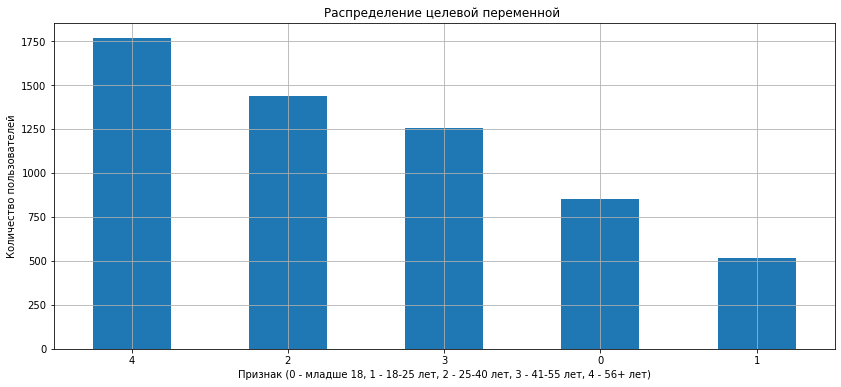

In [45]:
plt.figure(figsize=(14,6))
df['age_category'].value_counts().plot(
    kind = 'bar',
    title = f'Распределение целевой переменной ',
    ylabel = 'Количество пользователей',
    xlabel = 'Признак (0 - младше 18, 1 - 18-25 лет, 2 - 25-40 лет, 3 - 41-55 лет, 4 - 56+ лет)',
    rot = 0)

plt.grid()
plt.show()

In [46]:
print ('Распределение целевой переменной')
a = pd.concat ([df['age_category'].value_counts(),
              (df['age_category'].value_counts (normalize = True)*100)],axis = 1)
a.columns = ['количество', 'доля,%']
print (a, '\n')
print ('Уникальные значения', df['age_category'].unique())

Распределение целевой переменной
              количество  доля,%
age_category                    
4                   1766 30.3124
2                   1439 24.6996
3                   1254 21.5242
0                    853 14.6413
1                    514  8.8225 

Уникальные значения [4 2 0 1 3]


Целевая переменная `age_category` является многоклассовой и принимает пять значений:

- 0 — младше 18 лет;
- 1 — 18–25 лет;
- 2 — 25–40 лет;
- 3 — 41–55 лет;
- 4 — 56 лет и старше.

В выборке представлены все пять классов. Наиболее многочисленной является категория `4` — 1 766 пользователей (30,31%), далее следуют категории `2 `— 1 439 (24,70%) и `3` — 1 254 (21,52%). Категория `0` представлена 853 пользователями (14,64%), а наименее многочисленной является категория `1` — 514 пользователей (8,82%).

Таким образом, распределение целевой переменной неравномерное: доля наиболее многочисленного класса (4) примерно в 3,4 раза превышает долю наименее представленного класса (1). При построении многоклассовых моделей `Logistic Regression` и `SVC `необходимо учитывать этот дисбаланс. Для оценки качества моделей целесообразно использовать macro F1-score, а также матрицу ошибок. Macro F1 позволит одинаково учитывать качество классификации всех пяти возрастных категорий, включая наименее представленную.

<h3 id="section42">4.2. Наличие пропусков в данных</h3>

При первичном анализе были обнаружены пропуски в данных. Выведем их абсолютное и относительное значения.

In [47]:
def show_missing_stats (val):
    missing_stats = pd.DataFrame ({
        'Количество пропусков': val.isnull().sum(),
        'Доля пропусков,%': val.isnull().mean()*100
    })
    missing_stats = missing_stats[missing_stats['Количество пропусков']>0]
    
    if missing_stats.empty:
        return 'Пропусков в данных нет'
    
    missing_stats['Доля пропусков,%'] = missing_stats['Доля пропусков,%'].round(2)
    return missing_stats

show_missing_stats (df)

,Количество пропусков,"Доля пропусков,%"
ads_activity,233,4.0000
surf_depth,111,1.9100
primary_device,157,2.6900
cloud_usage,146,2.5100


Анализ пропусков показал, что они присутствуют только в четырёх признаках: `ads_activity`, `surf_depth`, `primary_device` и `cloud_usage`. Наибольшая доля пропусков наблюдается в `ads_activity` — 233 значения (4,00%). В `primary_device`, `cloud_usage` и `surf_depth` доля пропусков составляет соответственно 2,69%, 2,51% и 1,91%.

В целом количество пропусков невелико и не превышает 4% по отдельным признакам. При этом пропуски не затрагивают целевую переменную `age_category` и большинство признаков, поэтому удаление строк с пропусками привело бы к небольшой, но ненужной потере наблюдений. Для признаков `ads_activity`, `surf_depth`, `primary_device` пропуски можно заполнить категорией `'unknown'`, чтобы модель самостоятельно определила, связано ли наличие пропуска с возрастной категорией. Для `cloud_usage` пропуски рекомендуется заполнить значением `False`, так как по смыслу формирования таблицы запись создавалась для пользователей с `cloud_usage=True`, вероятно, отсутствие информации связано с тем, что пользователь не использует облачные ресурсы.

<h3 id="section44">4.4. Дубликаты</h3>

Проверим наличие дубликатов в данных.

In [48]:
df.duplicated().sum()

0

In [49]:
df.duplicated(subset = df.columns.drop('user_id')).sum()

0

Дубликатов в данных не обнаружено.

<h3 id="section45">4.5. Анализ категориальных признаков</h3>

Выделим категориальные признаки:

In [50]:
categorical_cols = ['peak_daytime',
                    'ads_activity',
                    'surf_depth',
                    'primary_device',
                    'cloud_usage'
                    ]

По порядку проведем анализ признаков `categorical_features`. Начнем с `peak_daytime`.

In [51]:
def describe_func (df, col):
    # Распределение категорий
    plt.figure (figsize=(10,6))
    
    df[col].value_counts().plot(
                kind='bar',
                rot=0,
                legend=False,
                title=f'Распределение пользователей по значениям признака {col}')

    plt.xlabel('Категория')
    plt.ylabel('Количество пользователей')
    plt.grid()
    plt.show()
    
    print (f'Статистические показатели по признаку {col}:')
    print (df[col].describe(), '\n')
    
    print ('Уникальные значения:', df[col].unique(), '\n')
    
    print ('Доля пропусков:', df[col].isna().mean().round(2), '\n')
    
    a = pd.concat ([df[col].value_counts(dropna=False),
              (df[col].value_counts (normalize = True)*100).round(2)],axis = 1)
    a.columns = ['количество', 'доля,%']
    print (a, '\n') 

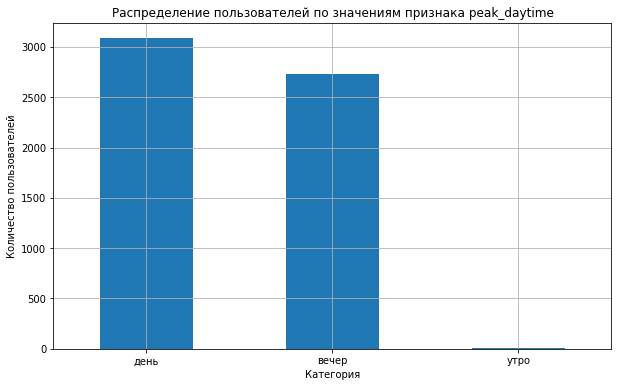

Статистические показатели по признаку peak_daytime:
count     5826
unique       3
top       день
freq      3087
Name: peak_daytime, dtype: object 

Уникальные значения: ['день' 'вечер' 'утро'] 

Доля пропусков: 0.0 

              количество  доля,%
peak_daytime                    
день                3087 52.9900
вечер               2735 46.9400
утро                   4  0.0700 



In [52]:
describe_func (df, 'peak_daytime')

Большинство пользователей имеют пиковую активность `днём` или `вечером`, тогда как категория `утро` представлена всего четырьмя пользователями. Пропуски в признаке отсутствуют. 

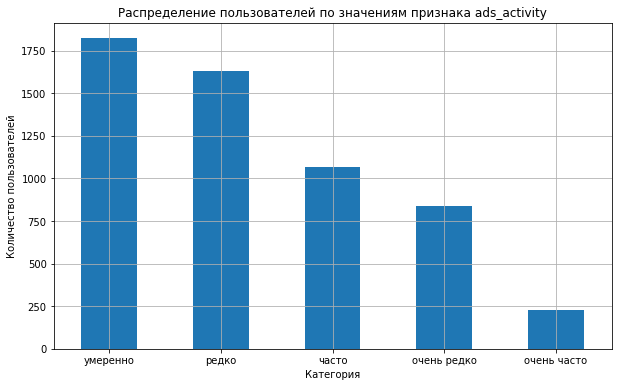

Статистические показатели по признаку ads_activity:
count         5593
unique           5
top       умеренно
freq          1824
Name: ads_activity, dtype: object 

Уникальные значения: [nan 'умеренно' 'редко' 'очень редко' 'очень часто' 'часто'] 

Доля пропусков: 0.04 

              количество  доля,%
ads_activity                    
умеренно            1824 32.6100
редко               1634 29.2200
часто               1069 19.1100
очень редко          841 15.0400
NaN                  233     NaN
очень часто          225  4.0200 



In [53]:
describe_func (df, 'ads_activity')

В выборке заполнены данные для 5 593 пользователей, а 233 значения (4,0%) являются пропусками. Наиболее распространённая категория — `умеренно`: 1 824 пользователя (32,6%), далее `редко` — 1 634 (29,2%) и `часто` — 1 069 (19,1%). Категории `очень редко` и `очень часто` представлены 841 (15,0%) и 225 (4,0%) пользователями соответственно. Таким образом, распределение смещено в сторону умеренной и низкой рекламной активности, а категория `очень часто` является наименее представленной.

Пропуски (4,0%) рекомендуется заменить отдельной категорией `Unknown`, а для `Logistic Regression` и `SVC` использовать `One-Hot Encoding`.

Далее изучим признак `surf_depth`.

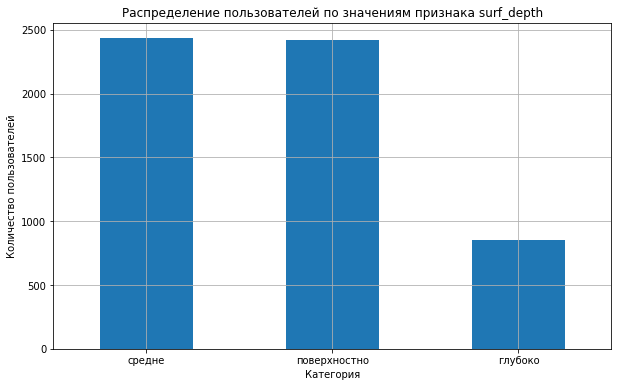

Статистические показатели по признаку surf_depth:
count       5715
unique         3
top       средне
freq        2435
Name: surf_depth, dtype: object 

Уникальные значения: ['глубоко' 'средне' 'поверхностно' nan] 

Доля пропусков: 0.02 

              количество  доля,%
surf_depth                      
средне              2435 42.6100
поверхностно        2424 42.4100
глубоко              856 14.9800
NaN                  111     NaN 



In [54]:
describe_func (df, 'surf_depth')

Наиболее распространены значения `средне` — 2 435 пользователей (42,6% ) и `поверхностно` — 2 424 пользователя (42,4%). Категория `глубоко` встречается значительно реже — 856 пользователей (15,0%). Таким образом, большинство пользователей характеризуются поверхностной или средней глубиной просмотра.

Признак содержит небольшую долю пропусков (1,91%). Пропуски рекомендуется заменить отдельной категорией `Unknown`.

Далее признак `primary_device`.

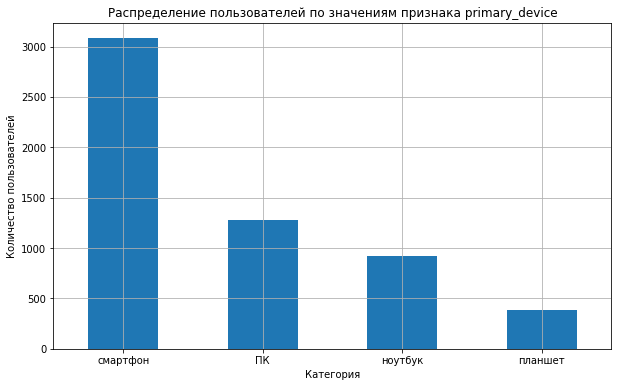

Статистические показатели по признаку primary_device:
count         5669
unique           4
top       смартфон
freq          3083
Name: primary_device, dtype: object 

Уникальные значения: ['смартфон' 'ноутбук' 'ПК' 'планшет' nan] 

Доля пропусков: 0.03 

                количество  доля,%
primary_device                    
смартфон              3083 54.3800
ПК                    1275 22.4900
ноутбук                923 16.2800
планшет                388  6.8400
NaN                    157     NaN 



In [55]:
describe_func (df, 'primary_device')

Признак `primary_device` имеет четыре категории - `смартфон`, `ПК`, `ноутбук` и `планшет` - и умеренный дисбаланс, обусловленный преобладанием смартфонов. Пропуски составляют 3% и рекомендуется заменить их отдельной категорией `Unknown`.

Признак `cloud_usage`.

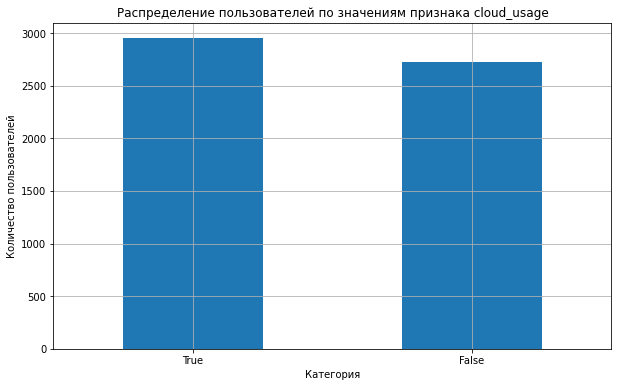

Статистические показатели по признаку cloud_usage:
count     5680
unique       2
top       True
freq      2951
Name: cloud_usage, dtype: object 

Уникальные значения: [False True nan] 

Доля пропусков: 0.03 

             количество  доля,%
cloud_usage                    
True               2951 51.9500
False              2729 48.0500
NaN                 146     NaN 



In [56]:
describe_func (df, 'cloud_usage')

Признак `cloud_usage` является бинарным категориальным признаком, характеризующим наличие обращения пользователя к облачным ресурсам. Среди пользователей 2 951 (52%) имеют значение `True` и 2 729 (48%) — `False`, поэтому основные категории представлены практически равномерно. Пропуски составляют 146 наблюдений (2,51%). Если пропуск в данном признаке означает отсутствие зафиксированного использования облачных ресурсов, его целесообразно заменить на `False`. Для подготовки данных к `Logistic Regression` и `SVC `бинарный признак рекомендуется представить в формате 0/1.

В ходе анализа рассмотрены пять категориальных признаков: `peak_daytime`, `ads_activity`, `surf_depth`, `primary_device` и `cloud_usage`.

Анализ распределений показал, что `peak_daytim`e в основном принимает значения `день` и `вечер`, тогда как категория `утро` представлена всего четырьмя наблюдениями. Для `ads_activity` преобладают умеренная и редкая рекламная активность. В `surf_depth` примерно одинаково представлены категории `средне` и `поверхностно`, тогда как глубокая навигация встречается реже. Для `primary_device` преобладают пользователи смартфонов, а наименее распространённым устройством является `планшет`. Признак `cloud_usage` характеризуется практически равным соотношением `True` и `False`.

Пропуски обнаружены в четырёх признаках. Их доля составляет от 1,91% до 4,00%. Для `ads_activity`, `surf_depth` и `primary_device` рекомендуется создать отдельную категорию `Unknown`, поскольку пропуск не позволяет однозначно определить категориальное значение. Для `cloud_usage` целесообразно заменить пропуски на `False`.

Для последующего построения моделей `Logistic Regression` и `SVC` категориальные признаки необходимо преобразовать в числовой формат. Для `peak_daytime`, `ads_activity`, `surf_depth` и `primary_device` рекомендуется использовать `One-Hot Encoding`. Бинарный признак `cloud_usage` после заполнения пропусков можно представить непосредственно в формате `0/1`.

<h3 id="section46">4.6. Анализ числовых признаков и выбросов</h3>

Выведем все числовые признаки:

In [57]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_cols.remove('age_category')

In [58]:
numeric_cols

['avg_sessions_per_day',
 'daytime_share_вечер',
 'daytime_share_день',
 'daytime_share_ночь',
 'category_share_Category 01',
 'category_share_Category 02',
 'category_share_Category 03',
 'category_share_Category 04',
 'category_share_Category 05',
 'category_share_Category 06',
 'category_share_Category 07',
 'category_share_Category 08',
 'category_share_Category 09',
 'category_share_Category 10',
 'category_share_Category 11',
 'category_share_Category 12',
 'category_share_Category 13',
 'category_share_Category 14',
 'category_share_Category 15',
 'category_share_Category 16',
 'category_share_Category 17',
 'category_share_Category 18',
 'category_share_Category 19',
 'category_unique',
 'weekday_share_0',
 'weekday_share_1',
 'weekday_share_2',
 'weekday_share_3',
 'weekday_share_4',
 'weekday_share_5']

Разделим анализ признаков по смыслу - сначала `avg_sessions_per_day`, потом доли активности `daytime_share`, затем блоком 20 признаков `category_share_` и после также отдельно `category_unique` и `weekday_share`.

In [59]:
def stat_func (col, xlabel):
    print (f'Статистические данные по признаку {col}:','\n')
    print (df[col].describe().round(2))
    
    # гистограмма
    fig, (ax1,ax2) = plt.subplots(2, 1, figsize=(14, 8),gridspec_kw={'height_ratios': [4, 2]})
    sns.histplot(
            data=df,
            x=col,
            bins=40,
            ax=ax1,
            kde=True # добавим линию kde на график
        )
    ax1.set_title(f'Распределение данных столбца {col}')
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel('Количество пользователей')
    ax1.grid()
       
    # диаграмма размаха
    sns.boxplot(
            data=df,
            x=col,
            ax=ax2
        )
    ax2.set_xlabel(xlabel)
    ax2.grid()
        
    plt.tight_layout()
    plt.show()
    
    print()

Статистические данные по признаку avg_sessions_per_day: 

count   5826.0000
mean      12.8700
std        5.3700
min        7.1400
25%        8.8600
50%       11.9300
75%       15.2100
max       59.9300
Name: avg_sessions_per_day, dtype: float64


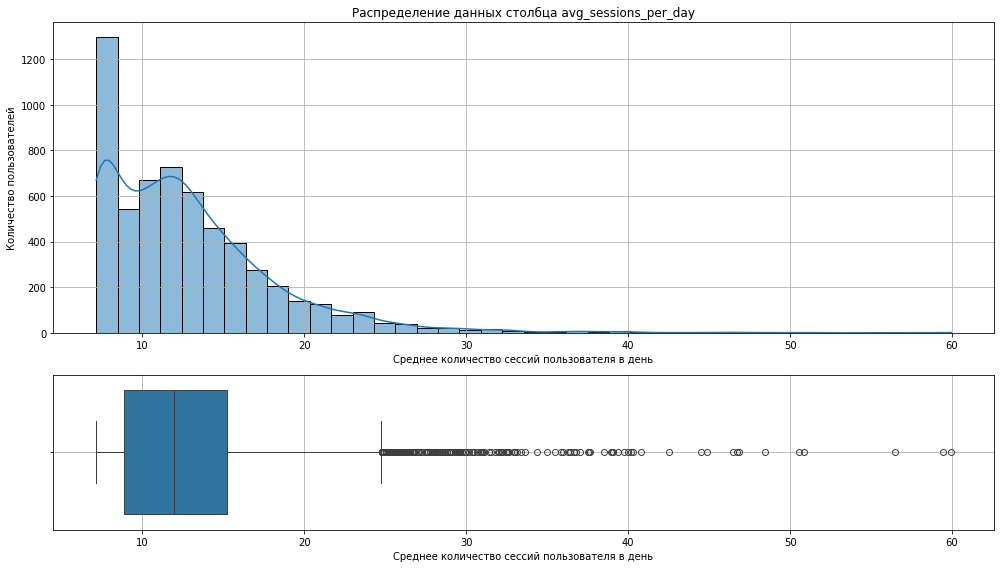

In [60]:
stat_func('avg_sessions_per_day','Среднее количество сессий пользователя в день')

Признак `avg_sessions_per_day` имеет выраженную правостороннюю асимметрию и выбросы. При этом экстремальные значения не выглядят очевидными ошибками и могут отражать реальную высокую активность пользователей, поэтому удалять или ограничивать их не рекомендуется. Для уменьшения влияния длинного правого хвоста целесообразно рассмотреть логарифмическое преобразование `log1p`.

Теперь проведем анализ долей активности в зависимости от времени суток.

Статистические данные по признаку daytime_share_вечер: 

count   5826.0000
mean       0.3600
std        0.0500
min        0.2100
25%        0.3200
50%        0.3600
75%        0.3900
max        0.5300
Name: daytime_share_вечер, dtype: float64


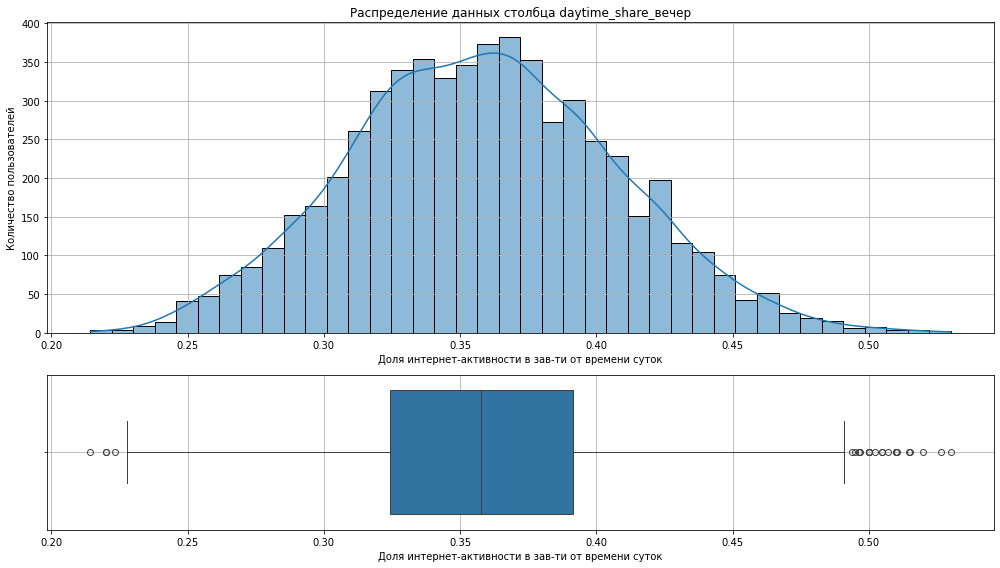



Статистические данные по признаку daytime_share_день: 

count   5826.0000
mean       0.3600
std        0.0500
min        0.2200
25%        0.3400
50%        0.3700
75%        0.4000
max        0.5300
Name: daytime_share_день, dtype: float64


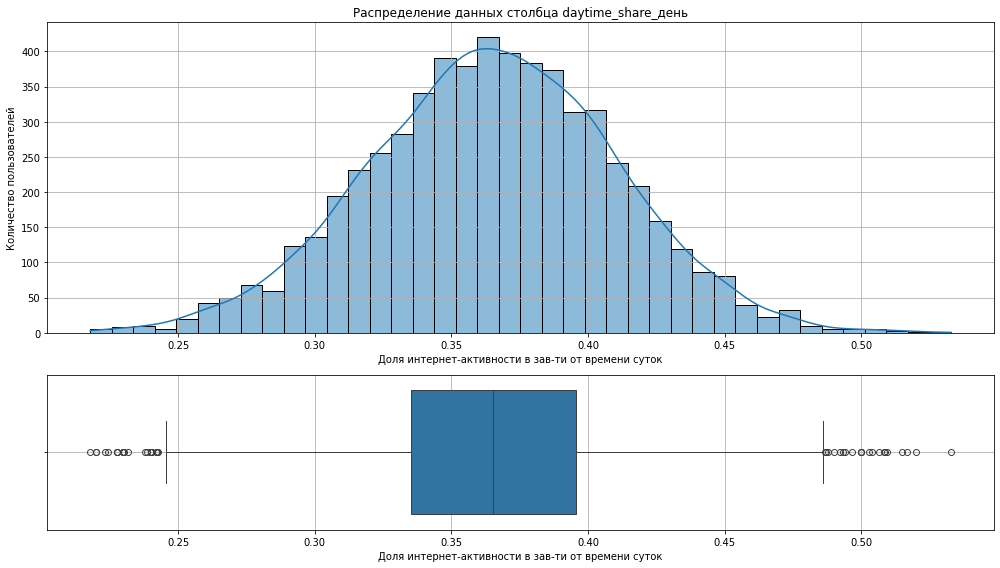



Статистические данные по признаку daytime_share_ночь: 

count   5826.0000
mean       0.0800
std        0.0200
min        0.0000
25%        0.0600
50%        0.0800
75%        0.0900
max        0.2000
Name: daytime_share_ночь, dtype: float64


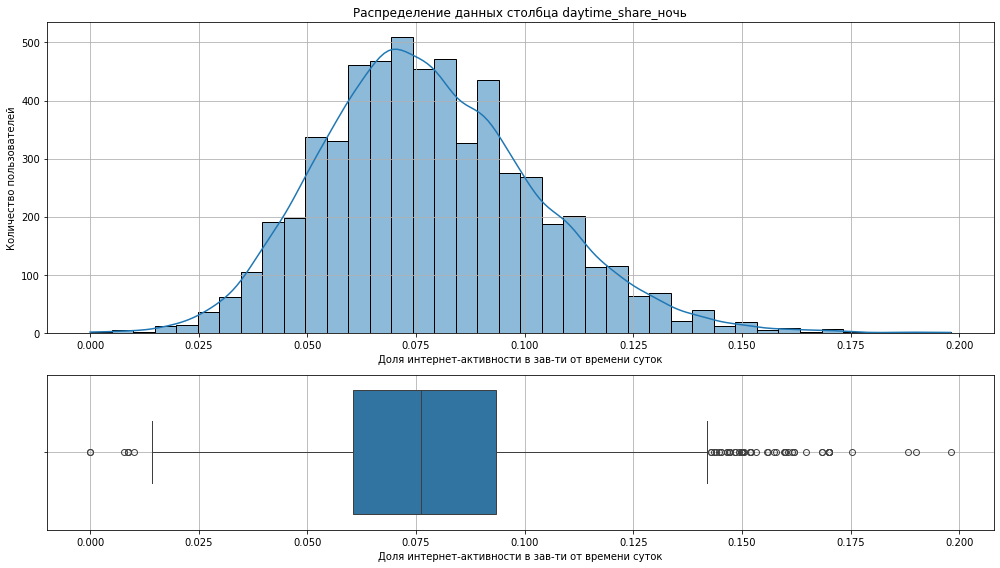

In [62]:
for col in ['daytime_share_вечер','daytime_share_день','daytime_share_ночь']:
    stat_func(col,'Доля интернет-активности в зав-ти от времени суток')
    print (f'=' * 40)
    print ()

В распределениях присутствуют формальные выбросы, однако они не являются очевидными ошибками. Они отражают пользователей с необычным распределением активности по времени суток.

Теперь проведем анализ доли активности пользователя в каждой категории.

Статистические данные по признаку category_share_Category 01: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0700
max        0.1800
Name: category_share_Category 01, dtype: float64


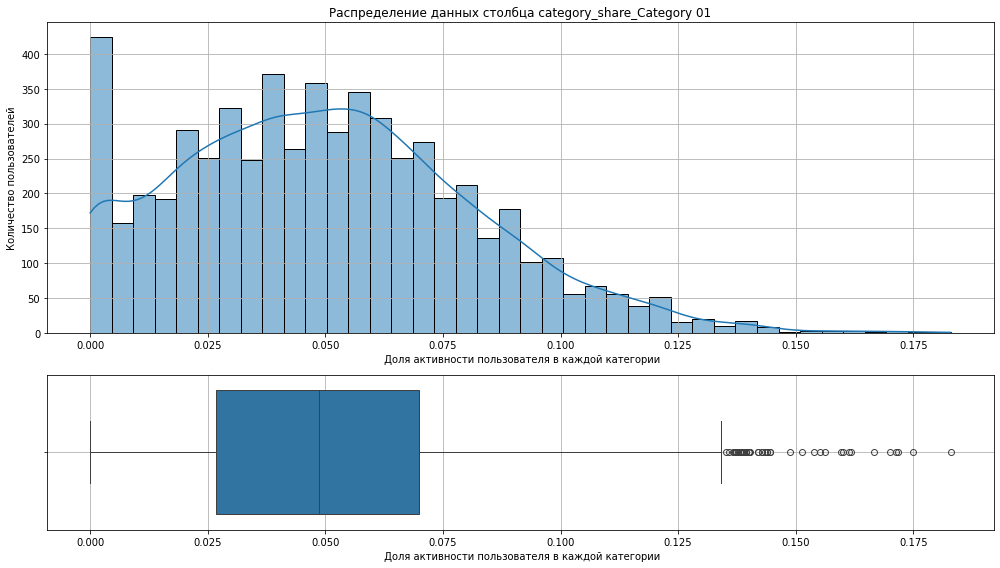



Статистические данные по признаку category_share_Category 02: 

count   5826.0000
mean       0.0400
std        0.0300
min        0.0000
25%        0.0200
50%        0.0400
75%        0.0600
max        0.1800
Name: category_share_Category 02, dtype: float64


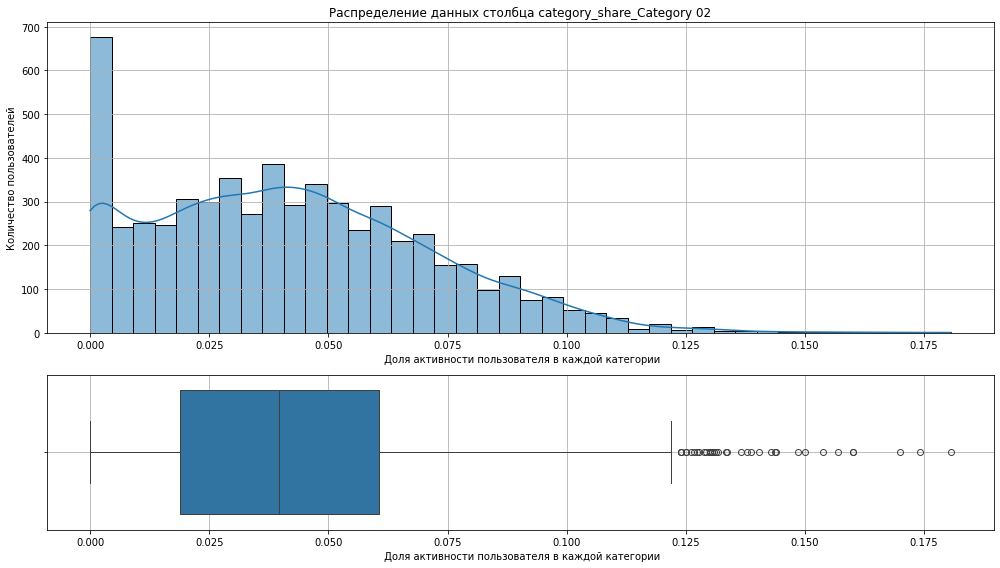



Статистические данные по признаку category_share_Category 03: 

count   5826.0000
mean       0.0700
std        0.0500
min        0.0000
25%        0.0200
50%        0.0600
75%        0.1000
max        0.2600
Name: category_share_Category 03, dtype: float64


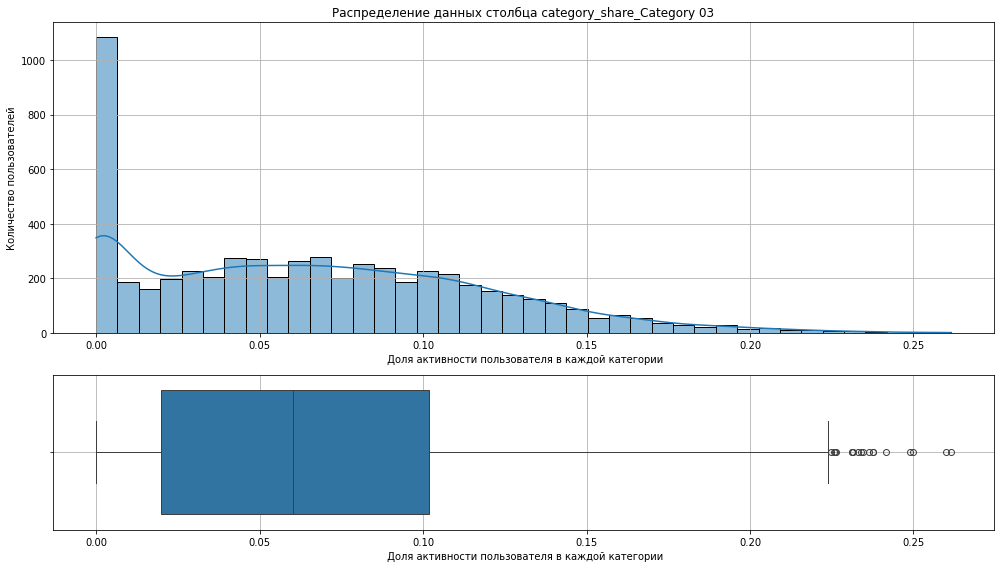



Статистические данные по признаку category_share_Category 04: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0700
max        0.1900
Name: category_share_Category 04, dtype: float64


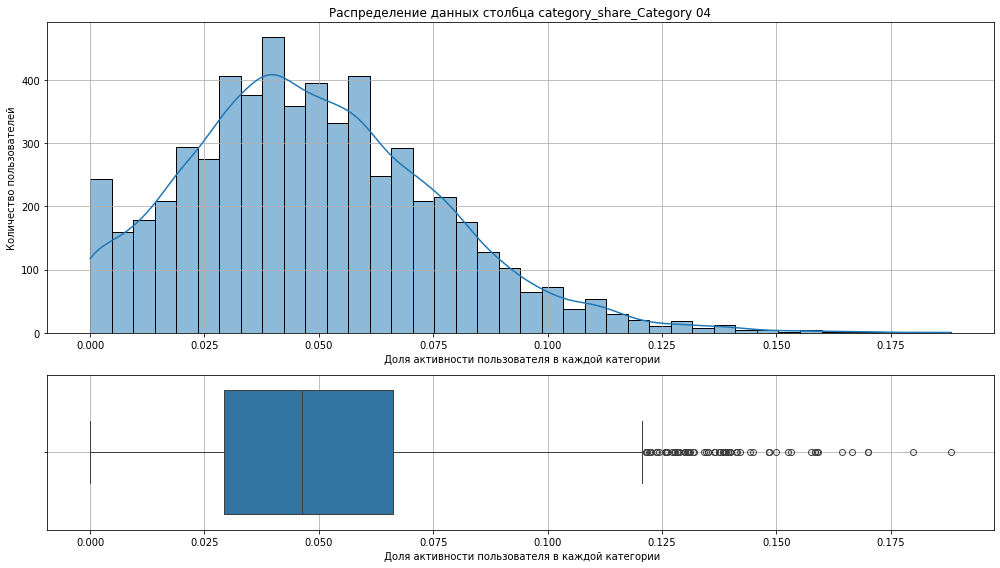



Статистические данные по признаку category_share_Category 05: 

count   5826.0000
mean       0.0600
std        0.0300
min        0.0000
25%        0.0400
50%        0.0600
75%        0.0800
max        0.1700
Name: category_share_Category 05, dtype: float64


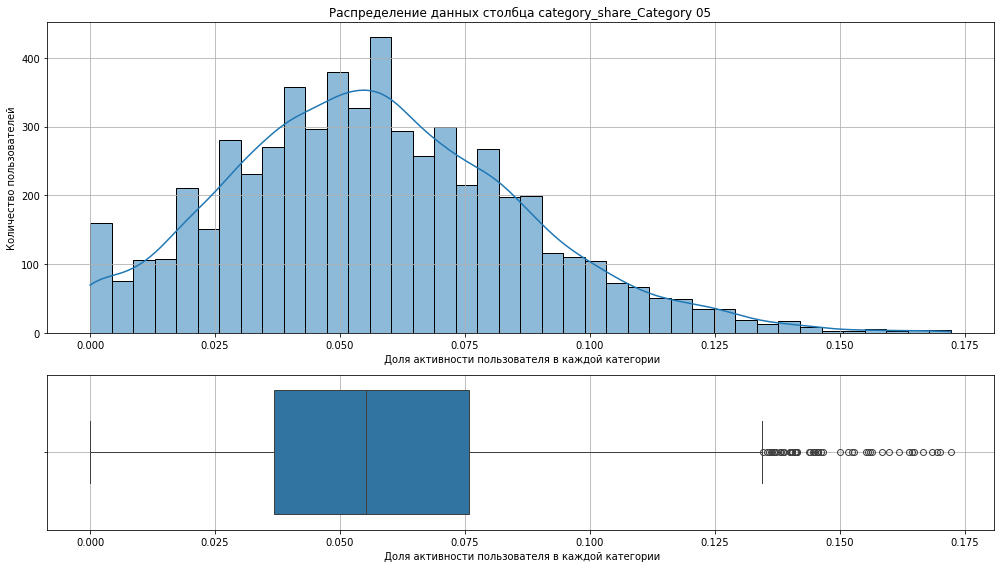



Статистические данные по признаку category_share_Category 06: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0700
max        0.1700
Name: category_share_Category 06, dtype: float64


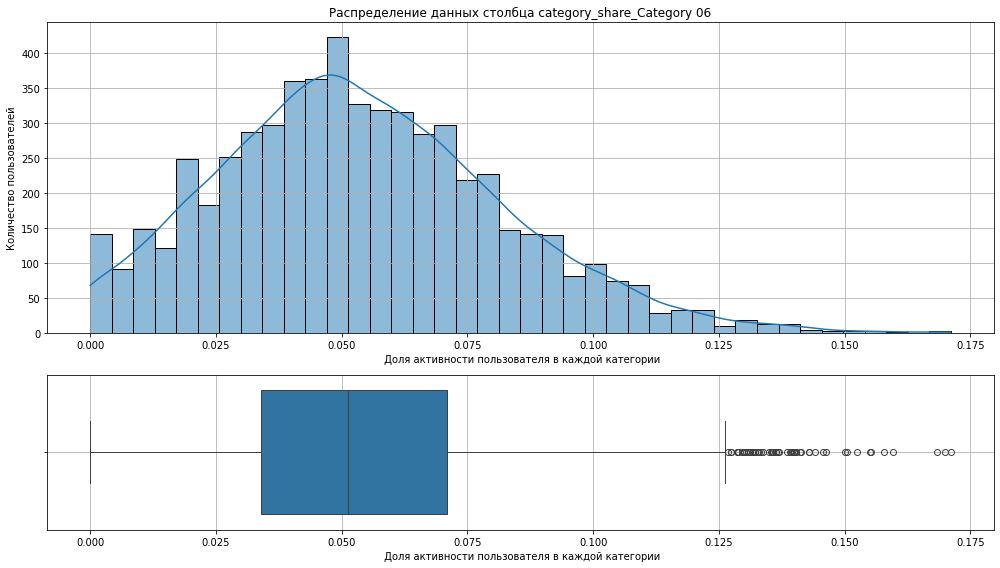



Статистические данные по признаку category_share_Category 07: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0700
max        0.1700
Name: category_share_Category 07, dtype: float64


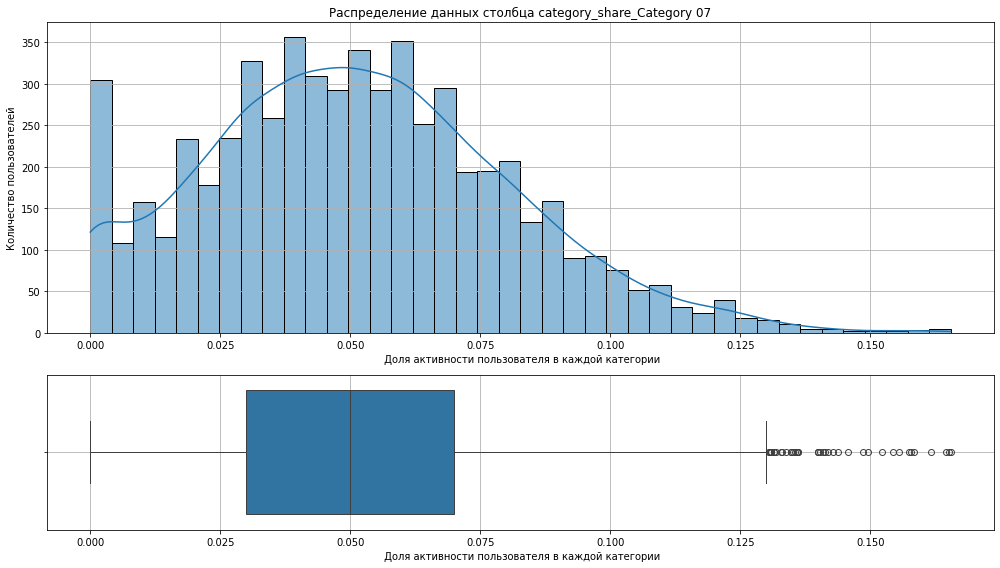



Статистические данные по признаку category_share_Category 08: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0700
max        0.1900
Name: category_share_Category 08, dtype: float64


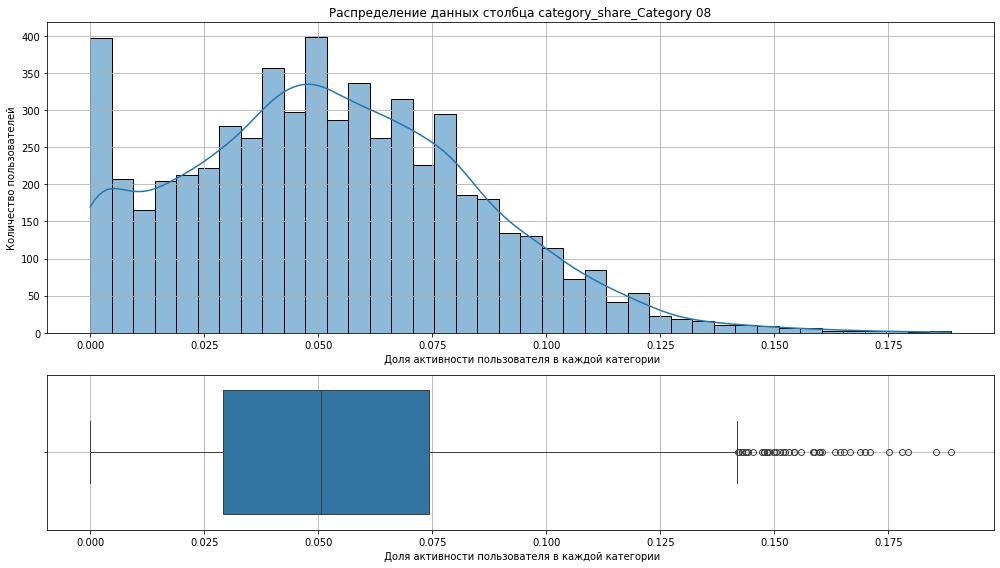



Статистические данные по признаку category_share_Category 09: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0700
max        0.1900
Name: category_share_Category 09, dtype: float64


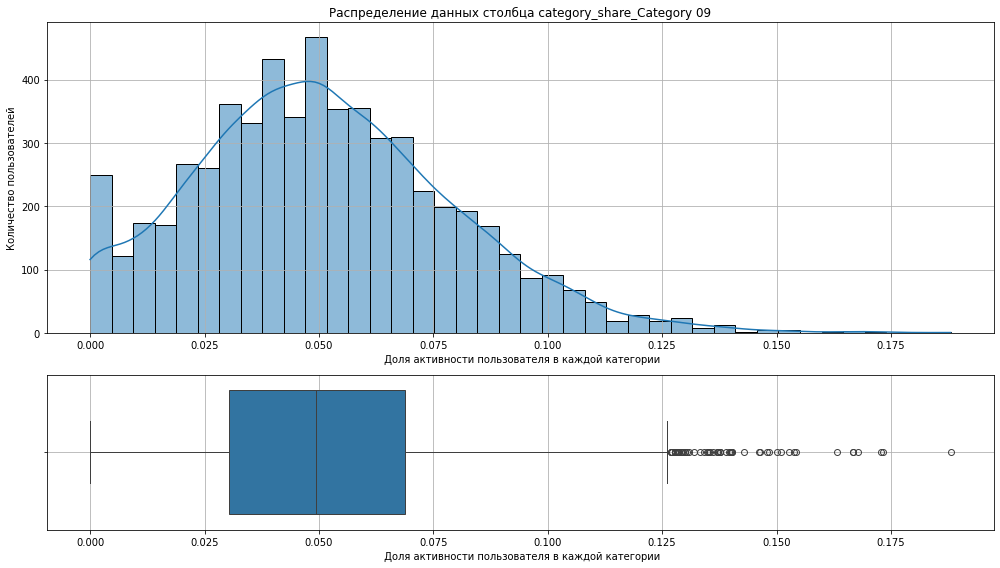



Статистические данные по признаку category_share_Category 10: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0700
max        0.2200
Name: category_share_Category 10, dtype: float64


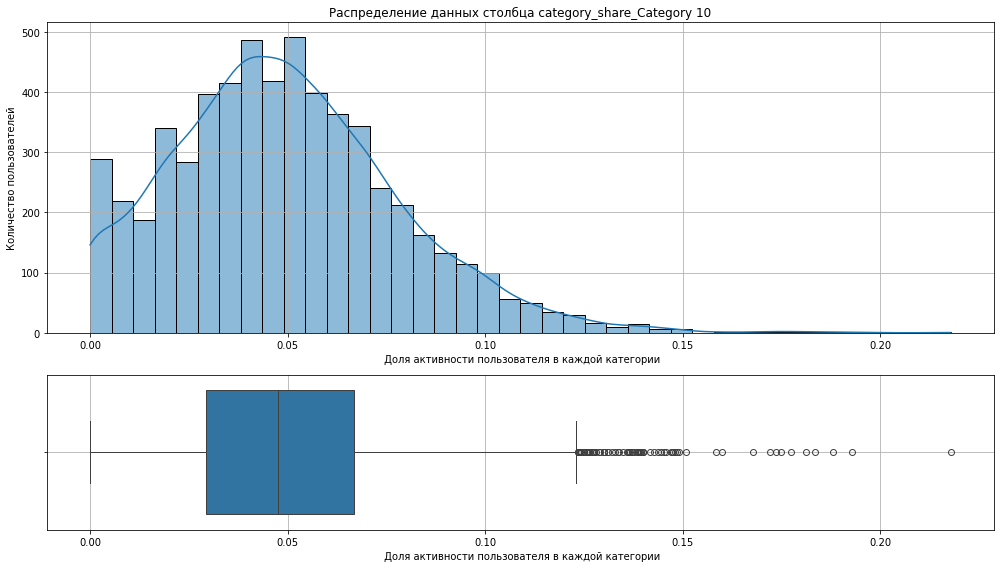



Статистические данные по признаку category_share_Category 11: 

count   5826.0000
mean       0.0400
std        0.0300
min        0.0000
25%        0.0200
50%        0.0300
75%        0.0500
max        0.1700
Name: category_share_Category 11, dtype: float64


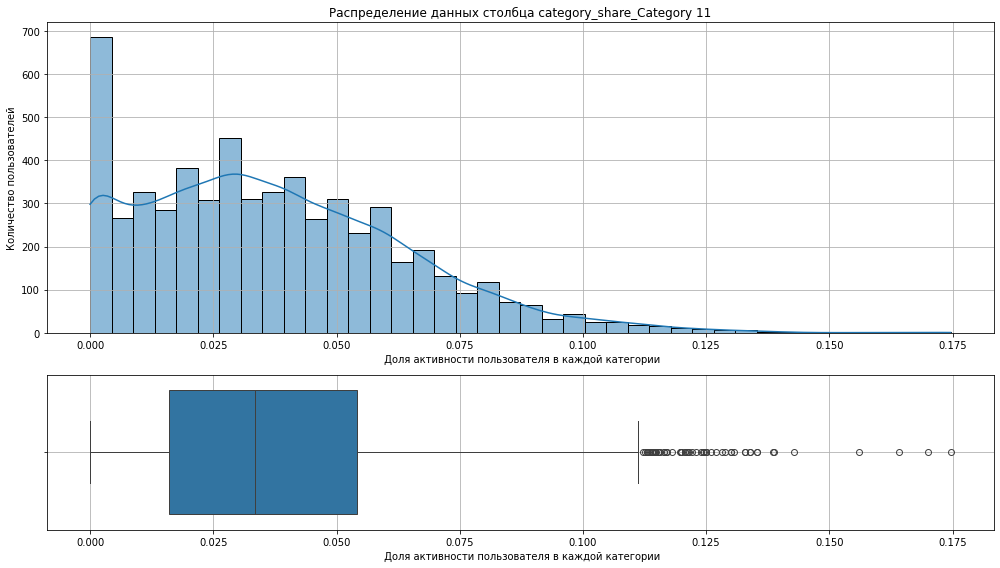



Статистические данные по признаку category_share_Category 12: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0200
50%        0.0500
75%        0.0700
max        0.1800
Name: category_share_Category 12, dtype: float64


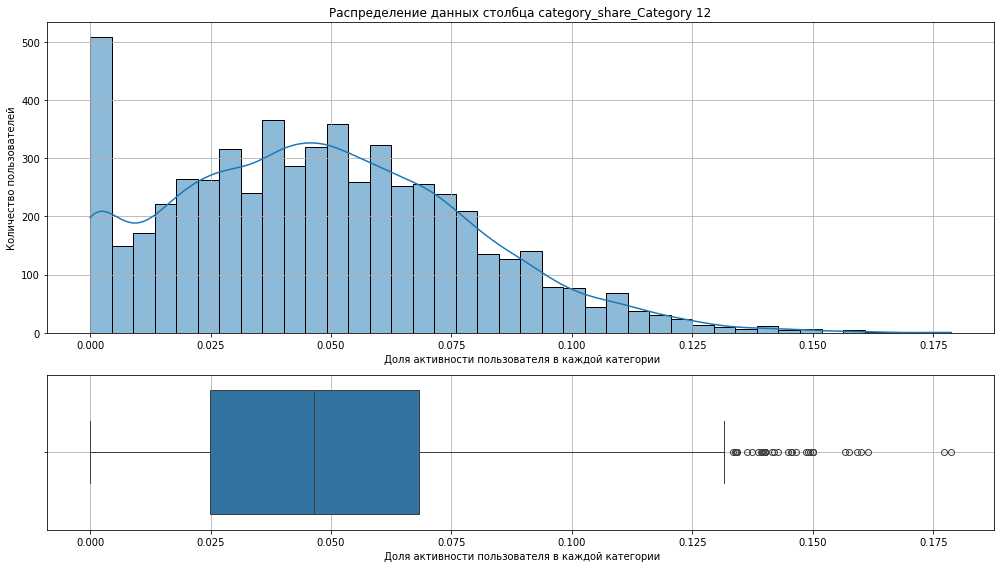



Статистические данные по признаку category_share_Category 13: 

count   5826.0000
mean       0.0600
std        0.0600
min        0.0000
25%        0.0100
50%        0.0600
75%        0.1000
max        0.3000
Name: category_share_Category 13, dtype: float64


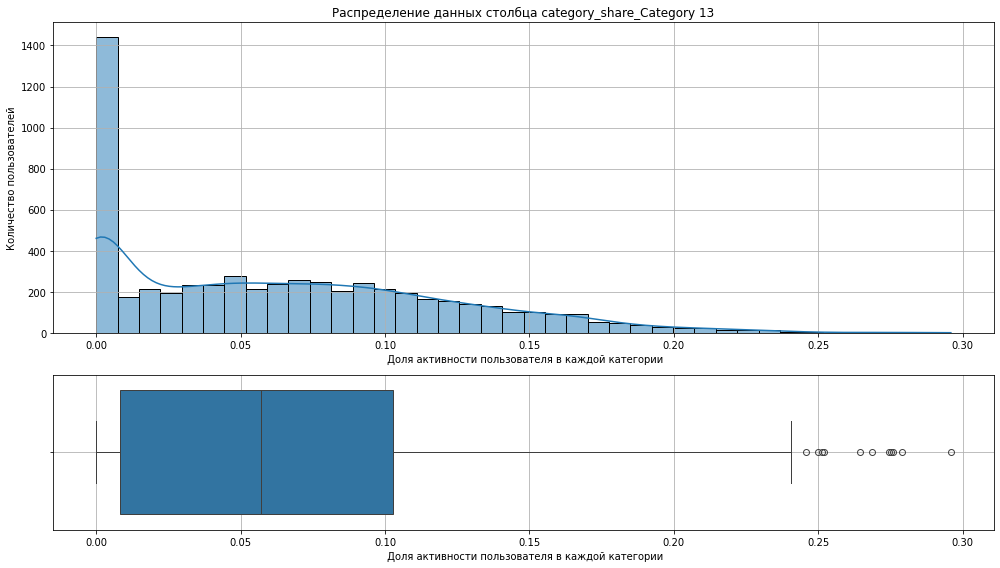



Статистические данные по признаку category_share_Category 14: 

count   5826.0000
mean       0.0400
std        0.0300
min        0.0000
25%        0.0200
50%        0.0400
75%        0.0600
max        0.1900
Name: category_share_Category 14, dtype: float64


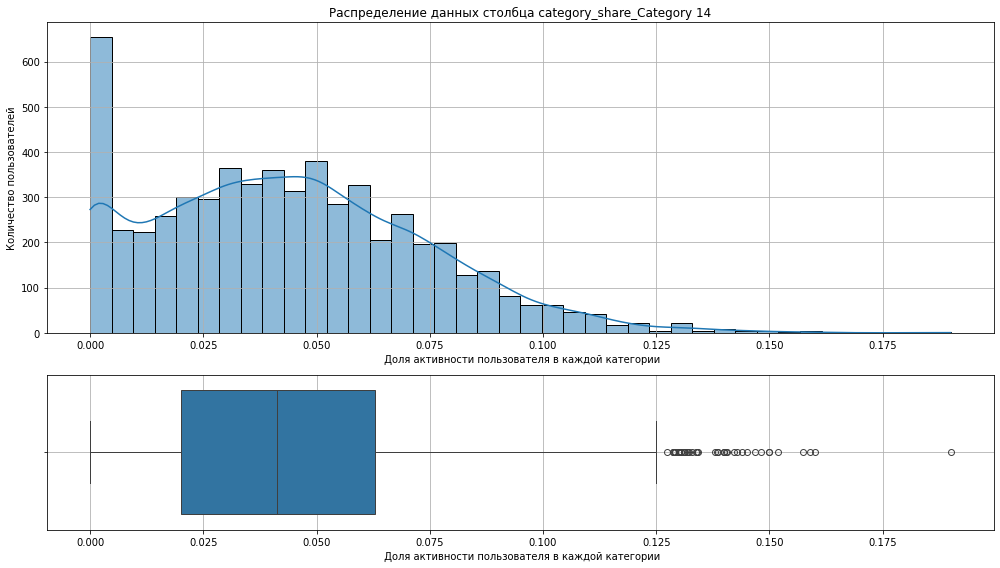



Статистические данные по признаку category_share_Category 15: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0700
max        0.2000
Name: category_share_Category 15, dtype: float64


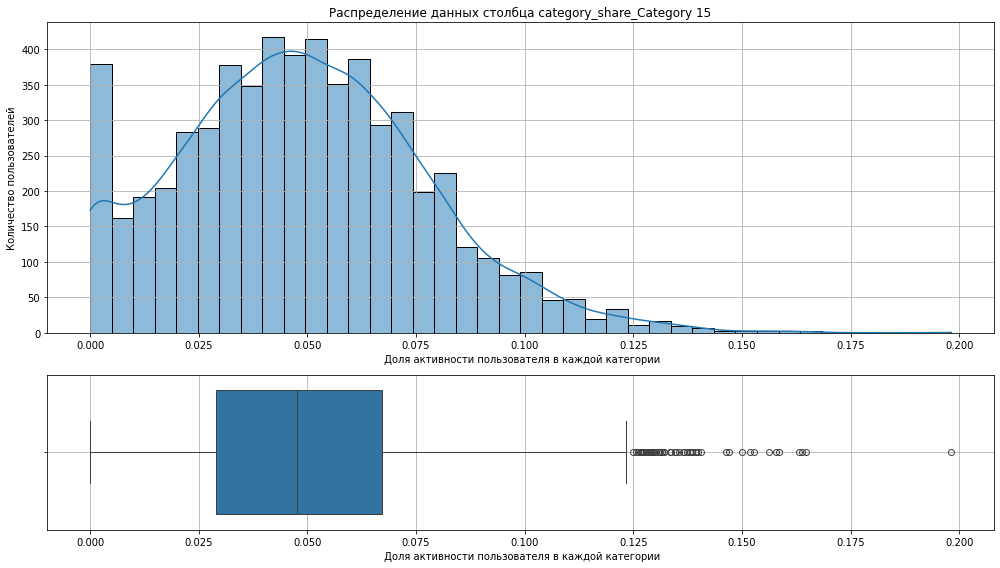



Статистические данные по признаку category_share_Category 16: 

count   5826.0000
mean       0.0400
std        0.0300
min        0.0000
25%        0.0200
50%        0.0400
75%        0.0600
max        0.1600
Name: category_share_Category 16, dtype: float64


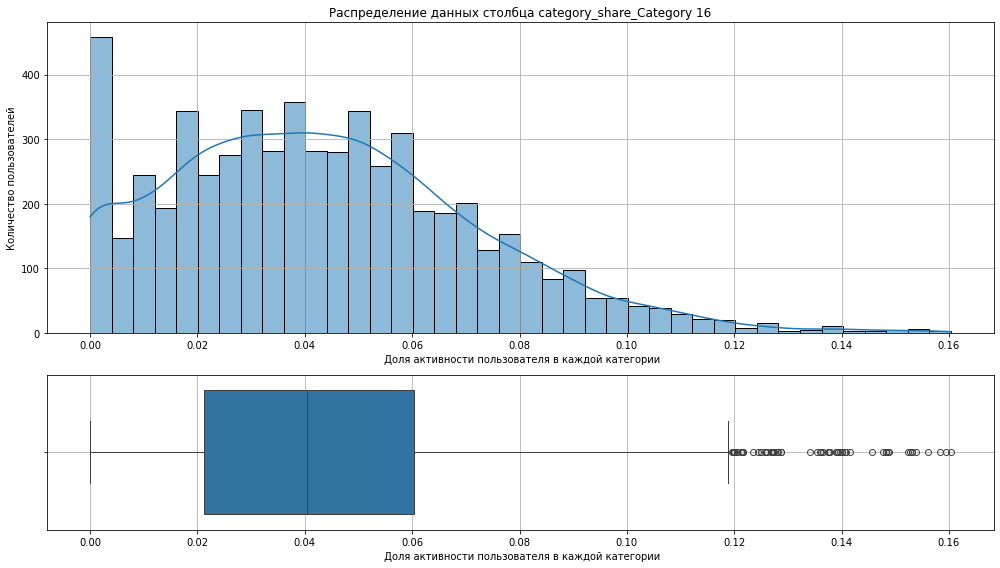



Статистические данные по признаку category_share_Category 17: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0600
max        0.1900
Name: category_share_Category 17, dtype: float64


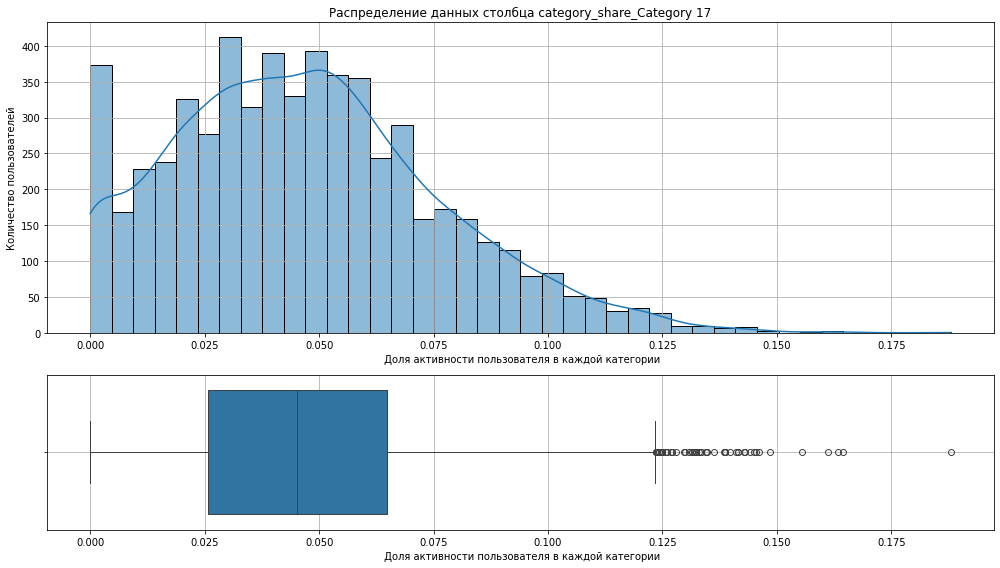



Статистические данные по признаку category_share_Category 18: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0200
50%        0.0400
75%        0.0700
max        0.2000
Name: category_share_Category 18, dtype: float64


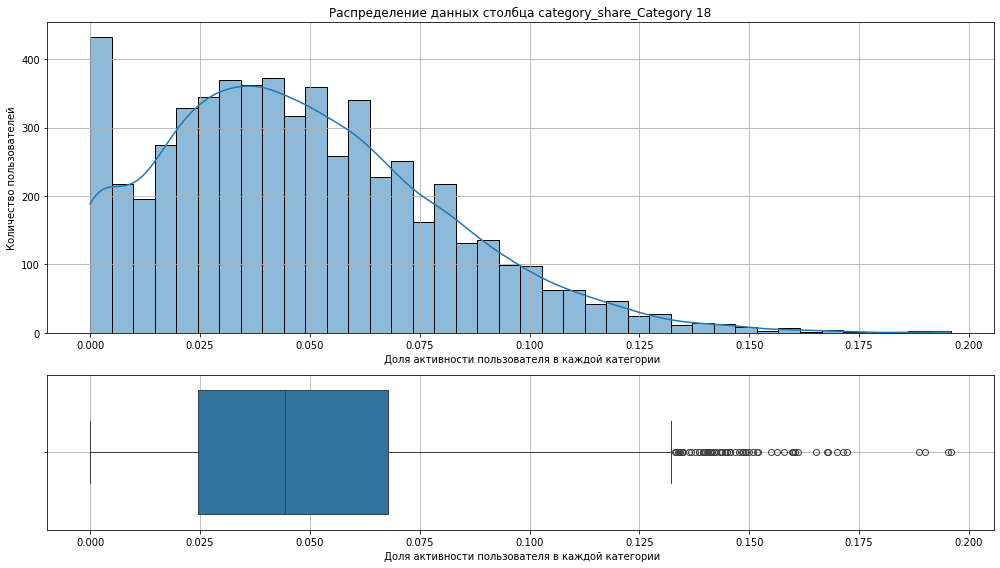



Статистические данные по признаку category_share_Category 19: 

count   5826.0000
mean       0.0500
std        0.0300
min        0.0000
25%        0.0300
50%        0.0500
75%        0.0700
max        0.1800
Name: category_share_Category 19, dtype: float64


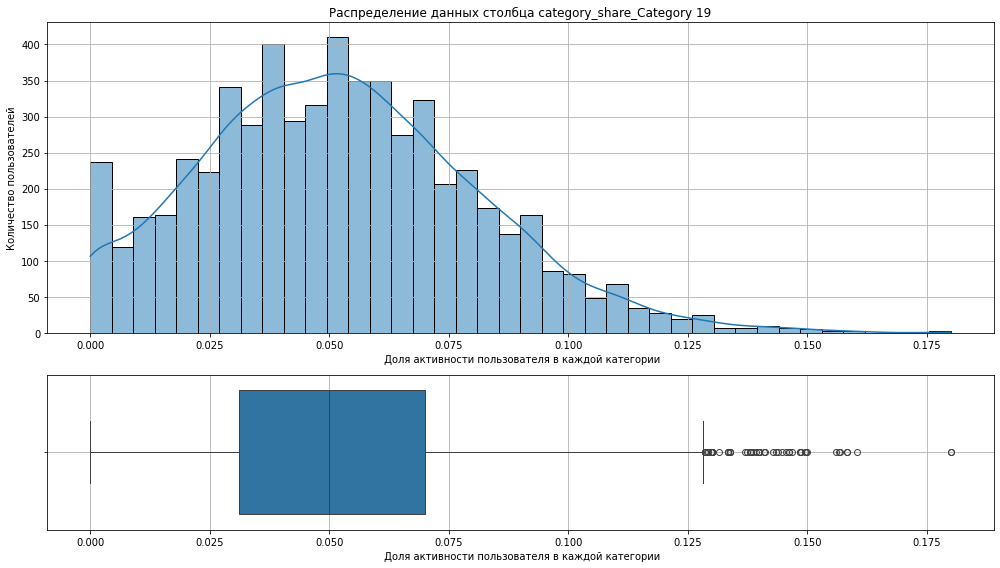

In [63]:
for col in ['category_share_Category 01',
            'category_share_Category 02',
            'category_share_Category 03',
            'category_share_Category 04',
            'category_share_Category 05',
            'category_share_Category 06',
            'category_share_Category 07',
            'category_share_Category 08',
            'category_share_Category 09',
            'category_share_Category 10',
            'category_share_Category 11',
            'category_share_Category 12',
            'category_share_Category 13',
            'category_share_Category 14',
            'category_share_Category 15',
            'category_share_Category 16',
            'category_share_Category 17',
            'category_share_Category 18',
            'category_share_Category 19']:
    stat_func(col,' Доля активности пользователя в каждой категории')
    print (f'=' * 40)
    print ()

Признаки `category_share` характеризуют долю активности пользователя в каждой из 20 категорий. Все признаки имеют одинаковый масштаб и ограничены снизу нулём. Распределения большинства признаков имеют правостороннюю асимметрию: основная масса наблюдений сосредоточена в области небольших значений, при этом присутствует длинный правый хвост.

Кроме того, все `category_share` являются частями одного общего распределения активности пользователя, поэтому они являются зависимыми признаками. Это означает потенциальную сильную мультиколлинеарность, которую необходимо проверить перед построением модели.

Изучим признак `category_unique`.

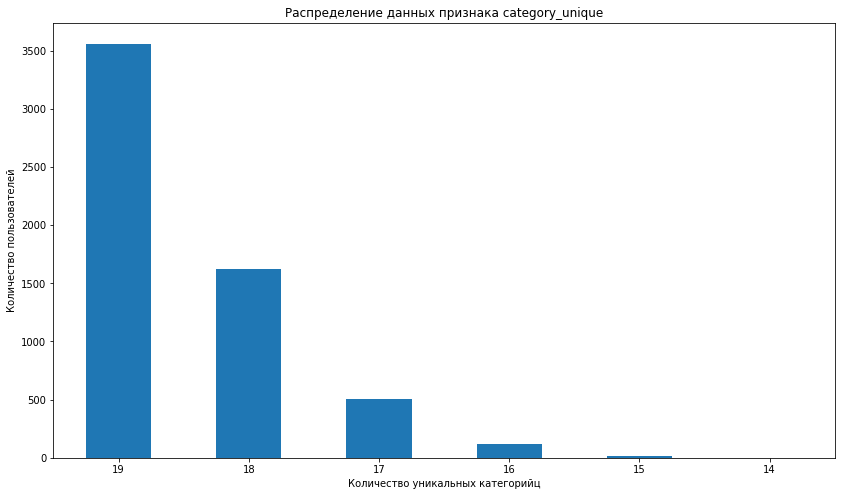

In [64]:
plt.figure(figsize=(14,8))
df['category_unique'].value_counts().plot(kind='bar',rot=0,
legend = False,
xlabel = 'Количество уникальных категорийц', ylabel = 'Количество пользователей',
title = f'Распределение данных признака category_unique')
plt.show()

In [65]:
print (f'Распределение по признаку category_unique:','\n')
print (df['category_unique'].value_counts(normalize = True).round(2))

Распределение по признаку category_unique: 

category_unique
19   0.6100
18   0.2800
17   0.0900
16   0.0200
15   0.0000
14   0.0000
Name: proportion, dtype: float64


Распределение смещено в сторону высоких значений: 61% пользователей взаимодействовали с `19` уникальными категориями, ещё 28% — с `18` категориями. Значения `17` и `16` встречаются значительно реже — около 9% и 2% соответственно.

При этом признак не требует преобразований: он дискретный и принимает всего несколько значений. На этапе дальнейшего отбора признаков целесообразно проверить его связь с таргетом. Если связь окажется слабой, `category_unique` можно будет исключить из итогового признакового пространства.

Изучим признаки доли активности по дням недели `weekday_share_`

Статистические данные по признаку weekday_share_0: 

count   5826.0000
mean       0.1400
std        0.0300
min        0.0400
25%        0.1200
50%        0.1400
75%        0.1600
max        0.2500
Name: weekday_share_0, dtype: float64


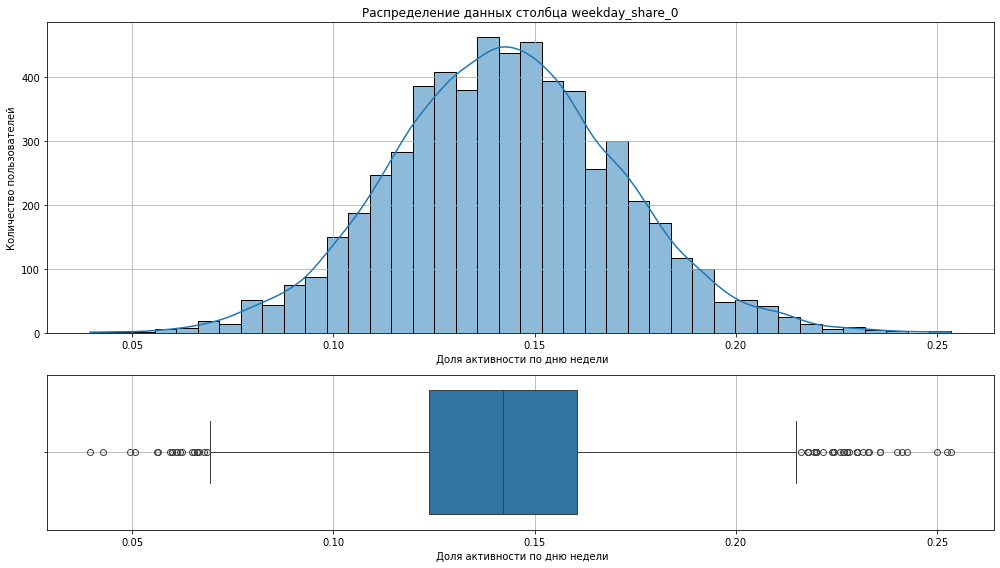



Статистические данные по признаку weekday_share_1: 

count   5826.0000
mean       0.1400
std        0.0300
min        0.0500
25%        0.1200
50%        0.1400
75%        0.1600
max        0.2600
Name: weekday_share_1, dtype: float64


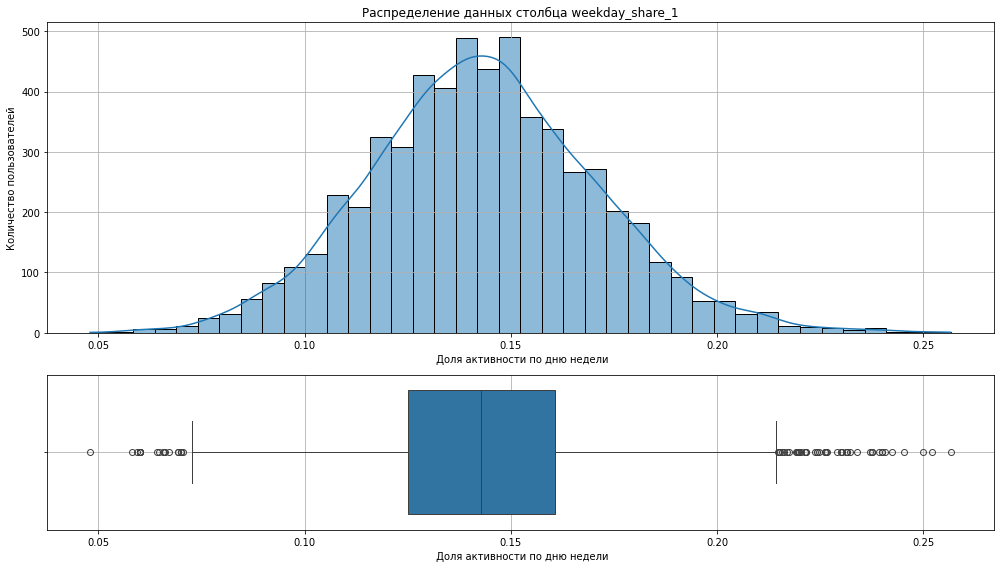



Статистические данные по признаку weekday_share_2: 

count   5826.0000
mean       0.1400
std        0.0300
min        0.0400
25%        0.1200
50%        0.1400
75%        0.1600
max        0.2600
Name: weekday_share_2, dtype: float64


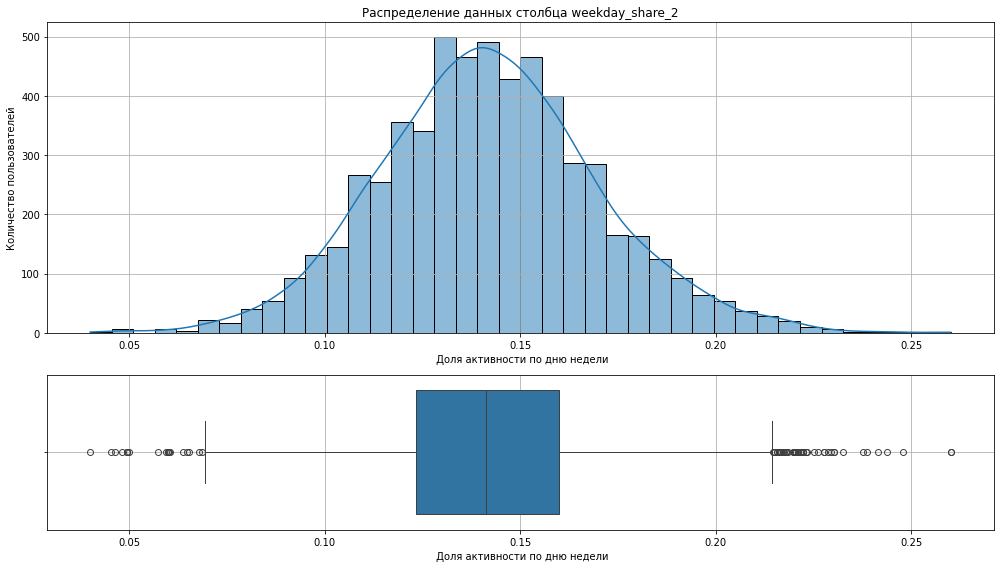



Статистические данные по признаку weekday_share_3: 

count   5826.0000
mean       0.1400
std        0.0300
min        0.0500
25%        0.1200
50%        0.1400
75%        0.1600
max        0.2700
Name: weekday_share_3, dtype: float64


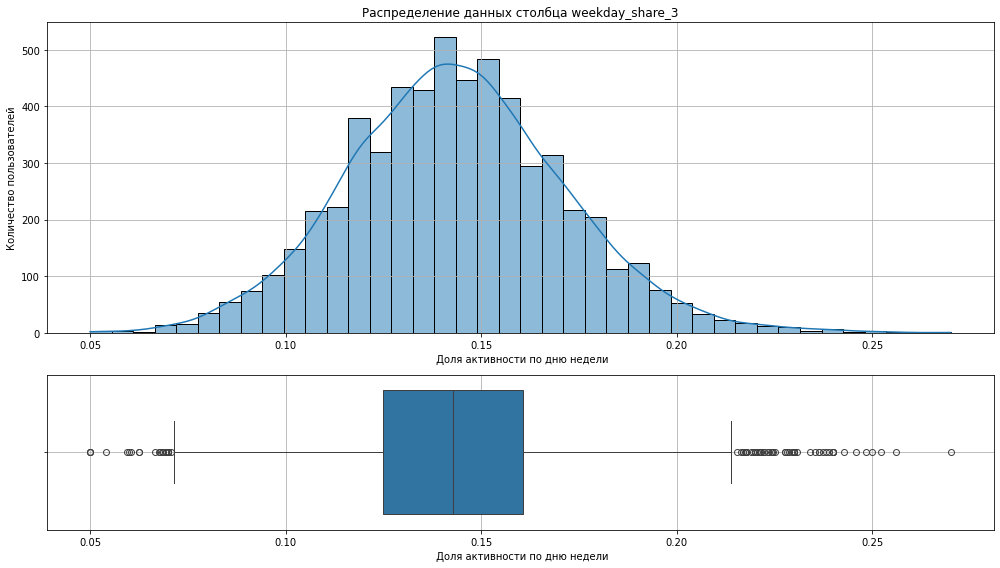



Статистические данные по признаку weekday_share_4: 

count   5826.0000
mean       0.1400
std        0.0300
min        0.0400
25%        0.1200
50%        0.1400
75%        0.1600
max        0.2800
Name: weekday_share_4, dtype: float64


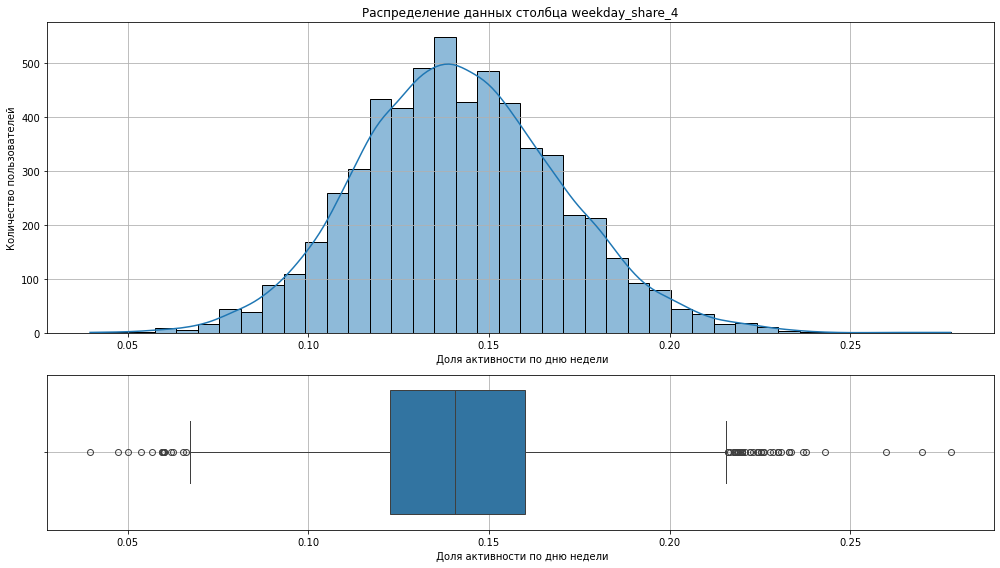



Статистические данные по признаку weekday_share_5: 

count   5826.0000
mean       0.1400
std        0.0300
min        0.0500
25%        0.1200
50%        0.1400
75%        0.1600
max        0.2600
Name: weekday_share_5, dtype: float64


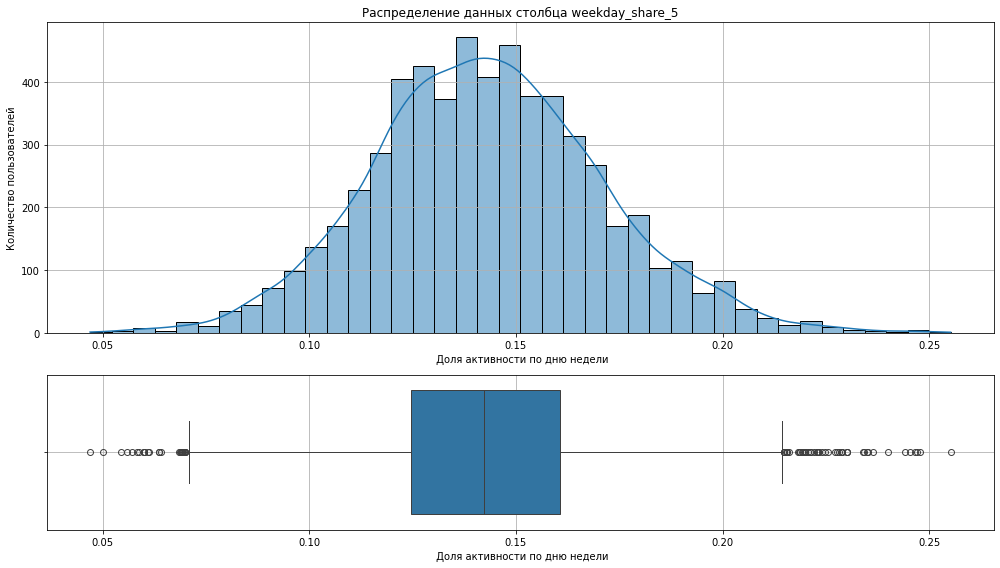

In [66]:
for col in ['weekday_share_0',
            'weekday_share_1',
            'weekday_share_2',
            'weekday_share_3',
            'weekday_share_4',
            'weekday_share_5']:
    stat_func(col,' Доля активности по дню недели')
    print (f'=' * 40)
    print ()

Распределения в целом близки к симметричным и сосредоточены в районе 0.12–0.16, при этом присутствуют отдельные выбросы пользователей с существенно большей или меньшей долей активности в конкретный день.
Признаки `weekday_share_0`–`weekday_share_6` сильно взаимосвязаны между собой, поскольку являются компонентами одного распределения и в сумме дают 1. Это означает наличие мультиколлинеарности. Перед обучением моделей необходимо проверить корреляцию между ними.

<h3 id="section47">4.7. Вывод</h3>

В результате анализа данных установлено, что в данных нет дубликатов, пропуски присутствуют только в четырёх признаках и не затрагивают целевую переменную. Целевая переменная `age_category` содержит пять возрастных категорий и характеризуется умеренным дисбалансом классов.

Сформированы следующие рекомендации для дальнейшего построения моделей:

- заполнить пропуски в категориальных признаках без удаления наблюдений;
- выполнить кодирование категориальных признаков с помощью One-Hot Encoding, а `cloud_usage` представить в формате 0/1;
- не удалять выбросы, поскольку они могут отражать реальные особенности поведения пользователей;
- масштабировать числовые признаки перед обучением;
- для `avg_sessions_per_day`  применить логарифмическое преобразование;
- проверить ценность `category_unique` и при слабой связи с целевой переменной рассмотреть его исключение;
- учитывать возможную избыточность признаков, являющихся компонентами одного распределения, несмотря на отсутствие критически высокой корреляции;
- при оценке использовать macro F1-score и матрицу ошибок, поскольку классы `age_category` представлены неравномерно.


<h3 id="section5">5. Предобработка данных</h3>

Перед обработкой данных необходимо провести разделение данных. Напишем функцию для подготовки признаков.

In [67]:
def prepare_df (df, target = None):
    df = df.copy()
    if target is None:    
        X = df.drop(columns = 'user_id')
    else:
        X = df.drop (columns = ['user_id', target])
        
    X['cloud_usage'] = X['cloud_usage'].map({True: 1,
                                             False: 0})  
    return X

Отделим признаки от таргета:

In [68]:
X = prepare_df (df, 'age_category')
y = df['age_category']

Разделим данные с учетом стратификации по целевой переменной в соотношении 80/20:

In [69]:
X_train, X_test, y_train, y_test = train_test_split (X,y,
                                                     test_size = 0.2,
                                                     stratify = y,
                                                     random_state = RANDOM_STATE)
print ('Размер обучающей выборки', X_train.shape)
print ('Размер тестовой выборки', X_test.shape)

Размер обучающей выборки (4660, 35)
Размер тестовой выборки (1166, 35)


In [70]:
print('Распределение классов в train:')
print(y_train.value_counts(normalize=True).sort_index().round(3))

print('\nРаспределение классов в test:')
print(y_test.value_counts(normalize=True).sort_index().round(3))

Распределение классов в train:
age_category
0   0.1460
1   0.0880
2   0.2470
3   0.2150
4   0.3030
Name: proportion, dtype: float64

Распределение классов в test:
age_category
0   0.1470
1   0.0880
2   0.2470
3   0.2150
4   0.3030
Name: proportion, dtype: float64


Определим списки признаков:

In [71]:
categorical_сols = ['peak_daytime', 
                    'ads_activity',
                    'surf_depth',
                    'primary_device']

binary_cols = ['cloud_usage']

numeric_cols = [col for col in X.columns 
               if col not in (categorical_сols + binary_cols)]

In [72]:
print('Категориальные:',len (categorical_сols), categorical_сols)
print()
print('Бинарные:', len (binary_cols), binary_cols)
print()
print('Числовые:', len (numeric_cols), numeric_cols)

Категориальные: 4 ['peak_daytime', 'ads_activity', 'surf_depth', 'primary_device']

Бинарные: 1 ['cloud_usage']

Числовые: 30 ['avg_sessions_per_day', 'daytime_share_вечер', 'daytime_share_день', 'daytime_share_ночь', 'category_share_Category 01', 'category_share_Category 02', 'category_share_Category 03', 'category_share_Category 04', 'category_share_Category 05', 'category_share_Category 06', 'category_share_Category 07', 'category_share_Category 08', 'category_share_Category 09', 'category_share_Category 10', 'category_share_Category 11', 'category_share_Category 12', 'category_share_Category 13', 'category_share_Category 14', 'category_share_Category 15', 'category_share_Category 16', 'category_share_Category 17', 'category_share_Category 18', 'category_share_Category 19', 'category_unique', 'weekday_share_0', 'weekday_share_1', 'weekday_share_2', 'weekday_share_3', 'weekday_share_4', 'weekday_share_5']


Проверим, есть ли в тренировочной выборке константные и квази-константные признаки.

In [73]:
vs_constant = VarianceThreshold(threshold =0)
vs_constant.fit(X_train[numeric_cols])
constant_num_cols = [col for col,keep in zip 
                     (numeric_cols,vs_constant.get_support()
                     ) if not keep]
print('Константные признаки:', constant_num_cols)

Константные признаки: []


In [74]:
quasi_num_cols = []

for col in numeric_cols:
    top_freq = X_train[col].value_counts(normalize=True).iloc[0]
    if top_freq >= 0.95:
        quasi_num_cols.append(col)
print('Квази-константные признаки:', quasi_num_cols)

Квази-константные признаки: []


Контантных и квази-константных признаков нет, поэтому не будем включать их в предобработку данных.

Напишем пайплайны для обработки признаков, для этого немного трансформируем числовой список столбцов, выделим один признак под логарифмирование.

In [75]:
categorical_сols = ['peak_daytime', 
                    'ads_activity',
                    'surf_depth',
                    'primary_device']

binary_cols = ['cloud_usage']

numeric_log_cols = ['avg_sessions_per_day']

numeric_cols = [col for col in X.columns 
               if col not in (categorical_сols + binary_cols + numeric_log_cols)]

In [76]:
categorical_pipeline = Pipeline ([
    ('imputer', SimpleImputer(strategy = 'constant', fill_value = 'Unknown')),
     ('encoder', OneHotEncoder(sparse_output = False, handle_unknown='ignore'))
     ])

In [77]:
binary_pipeline = Pipeline ([
   ('imputer', SimpleImputer(strategy = 'constant', fill_value = 0))
])

In [78]:
numeric_log_pipeline = Pipeline ([
    ('imputer', SimpleImputer(strategy = 'median')),
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

In [79]:
numeric_pipeline = Pipeline ([
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler', StandardScaler())
])

In [80]:
preprocessor = ColumnTransformer (transformers = [
    ('cat', categorical_pipeline, categorical_сols),
    ('bin', binary_pipeline, binary_cols),
    ('num_log',numeric_log_pipeline, numeric_log_cols),
    ('num', numeric_pipeline, numeric_cols)
])

<h3 id="section6">6. Обучение и оценка базовой модели</h3>

Обучим наивную базовую модель `DummyClassifier(strategy='stratified')`, которая строит предсказания, основываясь на распределении классов в обучающем наборе данных.

Для кросс-валидации используем `StratifiedKFold`, поскольку важно сохранить соотношение классов в каждом фолде.

In [81]:
N_FOLDS = 5

Зададим словарь с метриками:

In [82]:
scoring = {
    'f1_macro' : 'f1_macro',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro'
}

In [83]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

Функция для кросс-валидации:

In [84]:
def evaluate_model (name, pipeline):
    cv_res = cross_validate (pipeline,
                            X_train,
                            y_train,
                            cv = cv,
                            scoring = scoring,
                            n_jobs = -1
                            )
    return {
        'Model' :name,
        'f1_macro' : cv_res['test_f1_macro'].mean().round(3),
        'precision_macro' : cv_res['test_precision_macro'].mean().round(3),
        'recall_macro': cv_res['test_recall_macro'].mean().round(3)
    }

In [85]:
results = []

Наивная базовая модель:

In [86]:
base_pipeline = Pipeline ([
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='stratified', random_state=RANDOM_STATE))
])

In [87]:
results.append(evaluate_model('DummyClassifier', base_pipeline))

In [88]:
results

[{'Model': 'DummyClassifier',
  'f1_macro': 0.215,
  'precision_macro': 0.215,
  'recall_macro': 0.215}]

По результатам кросс-валидации базовая модель `DummyClassifier(strategy='stratified')` показала одинаковые значения всех трёх макро-метрик — `F1 = 0.215`, `precision = 0.215` и `recall = 0.215`. Это означает, что модель, которая делает случайные предсказания с учётом распределения классов, практически не использует информацию о признаках и даёт низкое качество классификации. Полученное значение `F1_macro = 0.215` является ориентиром для сравнения с более сложными моделями.

<h3 id="section7">7. Создание и отбор признаков</h3>

Сравним метрки моделей в трех вариантах:
- базовые модели без отбора признаков
- модели с селектором на основе корреляции с таргетом
- модели с отбором признаков на основе wrapper-методов

В качестве базовых моделей рассмотрим `Logistic Regression` и `SVC`. Поскольку задача является многоклассовой классификацией, для `SVC` проверим два подхода к работе с несколькими классами: стандартный вариант `SVC`, в котором многоклассовость обрабатывается внутри алгоритма, и стратегию `One-vs-Rest (OvR)`, при которой для каждого класса строится отдельный бинарный классификатор.

Для `SVC` дополнительно рассмотрим различные ядра — `linear`, `rbf` и `poly`. Это позволит сравнить как линейную зависимость между признаками и целевой переменной, так и нелинейные зависимости. В результате будут протестированы разные сочетания алгоритма, стратегии многоклассовой классификации и типа ядра.

При этом не будем существенно увеличивать количество моделей на последующих этапах, поскольку это приведет к большому числу комбинаций и усложнит сравнение результатов. Поэтому после оценки базовых вариантов для каждого типа модели выберем наиболее эффективную конфигурацию. В дальнейшем именно выбранные варианты `Logistic Regression` и `SVC` будем использовать для сравнения различных методов отбора признаков.

Построим пайплайны для моделей `LogisticRegression` и `SVC` с разными ядрами и оценим их.

In [89]:
LR_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE,max_iter=1000))

])

results.append(evaluate_model('Logistic Regression_base',LR_pipeline))

In [90]:
for kernel in ['linear', 'rbf', 'poly']:
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', SVC(kernel = kernel, random_state = RANDOM_STATE))
    ])

    results.append(evaluate_model(f'SVC_{kernel}_base', pipeline))

In [91]:
for kernel in ['linear', 'rbf', 'poly']:
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', OneVsRestClassifier(SVC(kernel = kernel, random_state = RANDOM_STATE)))
    ])

    results.append(evaluate_model(f'SVC_{kernel}_ovr', pipeline))

In [93]:
results = pd.DataFrame(results)
results.sort_values(by = 'f1_macro', ascending = False )

,Model,f1_macro,precision_macro,recall_macro
6,SVC_rbf_ovr,0.8920,0.9070,0.8840
3,SVC_rbf_base,0.8880,0.8920,0.8850
7,SVC_poly_ovr,0.8850,0.9040,0.8740
4,SVC_poly_base,0.8710,0.8960,0.8590
1,Logistic Regression_base,0.8200,0.8280,0.8160
2,SVC_linear_base,0.8200,0.8220,0.8190
5,SVC_linear_ovr,0.7860,0.8150,0.7780
0,DummyClassifier,0.2150,0.2150,0.2150


По результатам сравнения лучшей конфигурацией оказалась `SVC с RBF-ядром` и стратегией `One-vs-Rest`: она показала максимальный `f1_macro = 0.892`. При этом обычный `SVC` с RBF-ядром также показал высокий результат (0.888), но немного уступил OvR.

Для дальнейшей работы выбираем:

- SVC_linear_base — базовая конфигурация (в качестве сравнения);
- SVC с RBF-ядром + One-vs-Rest — лучшая конфигурация SVC;
- SVC с RBF-ядром;

Это позволит не увеличивать избыточно количество экспериментов и сосредоточиться на наиболее перспективных вариантах моделей.

### Отбор признаков на основе корреляции

Рассчитаем матрицу корреляций на тренировочной выборке.

In [94]:
#собираем датафрейм по train
train_df = X_train.copy()
train_df['age_category'] = y_train

In [95]:
corr_matrix = train_df.phik_matrix()
correlation_matrix = corr_matrix[corr_matrix.index!= 'age_category'][['age_category']].sort_values(by='age_category', ascending = False)

interval columns not set, guessing: ['avg_sessions_per_day', 'daytime_share_вечер', 'daytime_share_день', 'daytime_share_ночь', 'category_share_Category 01', 'category_share_Category 02', 'category_share_Category 03', 'category_share_Category 04', 'category_share_Category 05', 'category_share_Category 06', 'category_share_Category 07', 'category_share_Category 08', 'category_share_Category 09', 'category_share_Category 10', 'category_share_Category 11', 'category_share_Category 12', 'category_share_Category 13', 'category_share_Category 14', 'category_share_Category 15', 'category_share_Category 16', 'category_share_Category 17', 'category_share_Category 18', 'category_share_Category 19', 'category_unique', 'weekday_share_0', 'weekday_share_1', 'weekday_share_2', 'weekday_share_3', 'weekday_share_4', 'weekday_share_5', 'cloud_usage', 'age_category']


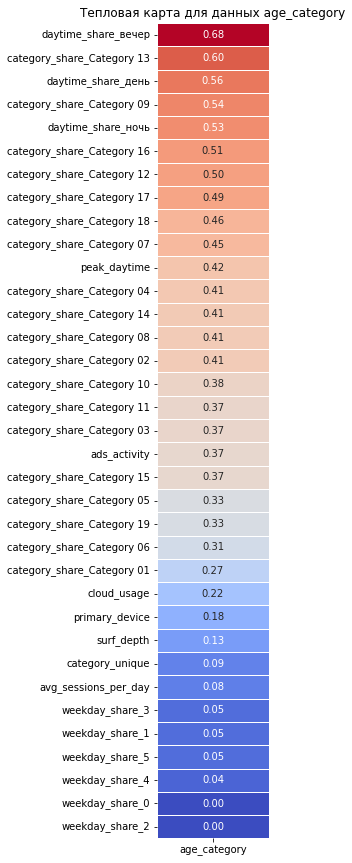

In [96]:
plt.figure(figsize=(2,15))

data_heatmap = correlation_matrix.loc[correlation_matrix.index!= 'age_category'][['age_category']].sort_values(by='age_category', ascending = False)
sns.heatmap(data_heatmap,
           annot=True,
           fmt='.2f',
           cmap='coolwarm',
           linewidths=0.5,
           cbar=False
           )

plt.yticks(rotation=0)
plt.title('Тепловая карта для данных age_category')
plt.show()

Построим полную матрицу корреляции признаков:

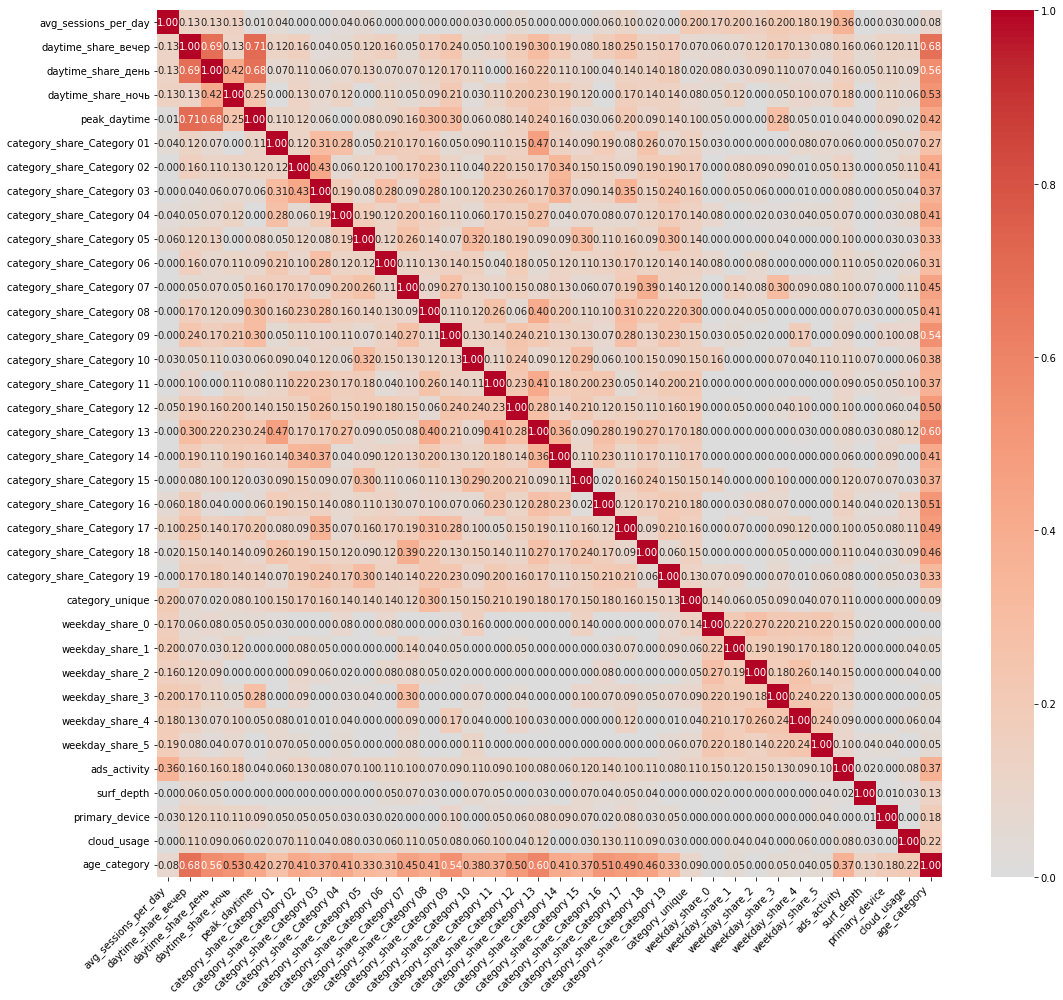

In [97]:
plt.figure(figsize=(16,14))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f', 
    cmap='coolwarm',
    center=0
)
plt.xticks(rotation=45, ha='right')  
plt.yticks(rotation=0)              
plt.tight_layout()
plt.show()

По результатам корреляционного анализа выявлено, что наиболее сильная связь с признаком `age_category` наблюдается у признаков, характеризующих временную активность пользователей: `daytime_share_вечер` (0.68), `daytime_share_день` (0.56), `daytime_share_ночь` (0.53) и `peak_daytime` (0.42). Также заметная положительная корреляция наблюдается с долями посещений отдельных категорий сайтов, наиболее выраженная для `category_share_Category 13` (0.60), `Category 09` (0.54), `Category 16` (0.51) и `Category 12` (0.50). Это указывает на связь возрастной категории пользователей с предпочитаемым временем посещения сайтов и структурой их интернет-активности.
При этом количество сессий в день `avg_sessions_per_day` практически не связано с возрастной категорией (0.08), как и большинство признаков, отражающих активность по дням недели. Слабые корреляции также наблюдаются у `surf_depth` (0.13), `primary_device` (0.18), `cloud_usage` (0.22) и `category_unique` (0.09).

Между признаками, описывающими доли посещений различных категорий, в целом отсутствуют чрезмерно высокие взаимные корреляции. Следовательно, выраженной мультиколлинеарности среди основных признаков не выявлено, а признаки можно использовать на последующих этапах построения моделей. При этом признаки с наиболее высокой корреляцией с `age_category` следует рассматривать как потенциально наиболее информативные для задачи классификации возрастных категорий пользователей.

 Для автоматизации отбора реализуем собственный трансформер `CorrelationSelector`. Для каждого признака рассчитывается Phik-корреляция с целевой переменной, после чего сохраняются признаки, для которых абсолютное значение корреляции превышает заданный порог `0.1`. Селектор включаем непосредственно в Pipeline, чтобы отбор признаков выполнялся внутри каждого этапа обучения модели и не происходило утечки информации.

После применения корреляционного отбора сравним качество `Logistic Regression` и `SVC` с различными ядрами.

In [98]:
from phik import phik_matrix

class CorrelationSelector(BaseEstimator, TransformerMixin):
    """
    Отбор признаков на основе Phik-корреляции с целевой переменной.
    Сохраняются признаки, для которых:
        Phik(feature, target) >= target_threshold
    """
    def __init__(self,target_threshold=0.1):
        self.target_threshold = target_threshold
        
    def fit(self, X, y):
        # работаем с DataFrame
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)
        if not isinstance(y, pd.Series):
            y = pd.Series(y, name="target")
        else:
            y = y.copy()
        # Имя target
        y.name = "target"
        # Объединяем признаки и target
        data = X.copy()
        data["target"] = y.values
        # Phik-матрица
        #phi_matrix = data.phik_matrix()
        phi_matrix = phik_matrix(data)
        # Phik каждого признака с target
        target_corr = phi_matrix["target"].drop("target").abs()
        # Отбираем признаки по порогу
        self.selected_features_ = (
            target_corr[target_corr >= self.target_threshold]
            .index
            .tolist())

        return self
                                   
    def transform(self, X):
        check_is_fitted(self)
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)
        return X.loc[:, self.selected_features_]

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self)
        return np.array(self.selected_features_)

Построим пайплайны c учетом `CorrelationSelector()`:

In [99]:
results1 = []

In [100]:
SVC_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', CorrelationSelector(target_threshold=0.1)),
    ('classifier', SVC(kernel = 'linear', random_state = RANDOM_STATE))
    ])
results1.append(evaluate_model(f'SVC_linear_corr', SVC_pipeline))

In [101]:
SVC_pipeline_rbf = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', CorrelationSelector(target_threshold=0.1)),
    ('classifier', OneVsRestClassifier(SVC(kernel = 'rbf', random_state = RANDOM_STATE)))
    ])
results1.append(evaluate_model(f'SVC_RBF_corr', SVC_pipeline_rbf))

In [102]:
SVC_pipeline_rbf_base = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', CorrelationSelector(target_threshold=0.1)),
    ('classifier', SVC(kernel = 'rbf', random_state = RANDOM_STATE))
    ])
results1.append(evaluate_model(f'SVC_RBF_base_corr', SVC_pipeline_rbf_base))

In [103]:
results1 = pd.DataFrame(results1)
results1.sort_values(by = 'f1_macro', ascending = False )

,Model,f1_macro,precision_macro,recall_macro
1,SVC_RBF_corr,0.9040,0.9140,0.8970
2,SVC_RBF_base_corr,0.9010,0.9050,0.8970
0,SVC_linear_corr,0.8250,0.8280,0.8240


Корреляционный отбор практически не изменил качество `SVC` с линейным ядром (F1_macro = 0.825 против 0.820 для базовой модели), но улучшил результаты для обеих моделей `SVC` с RBF-ядром (для стратегии OvR F1-macro вырос с 0.892 до 0.904, для базовой стратегии OvO c 0.888 до 0.901). Таким образом, для SVC данный способ отбора оказался эффективным.

### Отбор признаков на основе wrapper-методов

Далее перейдем к wrapper-методам отбора признаков. Для `SVC` с линейным ядром применим `RFECV`, поскольку модель имеют линейную структуру и позволяют эффективно оценивать важность признаков через коэффициенты. Для `SVC` с RBF-ядром используем `Sequential Feature Selection (SFS)`, поскольку нелинейное ядро не дает напрямую интерпретируемых коэффициентов важности, а `SFS` позволяет оценивать признаки непосредственно по качеству модели.

In [104]:
results2 = []

In [105]:
SVC_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('rfecv', RFECV(estimator=SVC(kernel = 'linear',random_state=RANDOM_STATE), 
                   step = 0.1, 
                   cv=3,
                   scoring = 'f1_macro',
                   n_jobs=-1)),
        ('classifier', SVC(kernel = 'linear', random_state = RANDOM_STATE))
    ])

results2.append(evaluate_model(f'SVC_linear_RFE', SVC_pipeline))

In [106]:
SVC_corr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', CorrelationSelector(target_threshold=0.1)),
    ('rfecv', RFECV(estimator=SVC(kernel = 'linear',random_state=RANDOM_STATE), 
                   step = 0.1, 
                   cv=3,
                   scoring = 'f1_macro',
                   n_jobs=-1)),
    ('classifier', SVC(kernel = 'linear', random_state = RANDOM_STATE))
    ])

results2.append(evaluate_model(f'SVC_linear_corr+RFE', SVC_corr_pipeline))

In [107]:
SVC_rbf_base_sfs_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('sfs', SFS(estimator=SVC(kernel = 'rbf',random_state=RANDOM_STATE), 
                    n_features_to_select='auto',
                    direction='forward',
                    scoring='f1_macro', 
                    cv=3,
                    n_jobs=-1)),
        ('classifier', SVC(kernel = 'rbf', random_state = RANDOM_STATE))
    ])

results2.append(evaluate_model(f'SVC_rbf_base_SFS', SVC_rbf_base_sfs_pipeline))

interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 1

In [108]:
SVC_rbf_base_corr_sfs_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', CorrelationSelector(target_threshold=0.1)),
    ('sfs', SFS(estimator=SVC(kernel = 'rbf',random_state=RANDOM_STATE), 
                    n_features_to_select='auto',
                    direction='forward',
                    scoring='f1_macro', 
                    cv=3,
                    n_jobs=-1)),
        ('classifier', SVC(kernel = 'rbf', random_state = RANDOM_STATE))
    ])

results2.append(evaluate_model(f'SVC_rbf_base+corr_SFS', SVC_rbf_base_corr_sfs_pipeline))

In [109]:
SVC_rbf_sfs_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('sfs', SFS(estimator=SVC(kernel = 'rbf',random_state=RANDOM_STATE), 
                    n_features_to_select='auto',
                    direction='forward',
                    scoring='f1_macro', 
                    cv=3,
                    n_jobs=-1)),
        ('classifier',  OneVsRestClassifier(SVC(kernel = 'rbf', random_state = RANDOM_STATE)))
    ])

results2.append(evaluate_model(f'SVC_rbf_SFS', SVC_rbf_sfs_pipeline))

In [110]:
SVC_rbf_corr_sfs_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', CorrelationSelector(target_threshold=0.1)),
    ('sfs', SFS(estimator=SVC(kernel = 'rbf',random_state=RANDOM_STATE), 
                    n_features_to_select='auto',
                    direction='forward',
                    scoring='f1_macro', 
                    cv=3,
                    n_jobs=-1)),
        ('classifier',  OneVsRestClassifier(SVC(kernel = 'rbf', random_state = RANDOM_STATE)))
    ])

results2.append(evaluate_model(f'SVC_rbf+corr_SFS', SVC_rbf_corr_sfs_pipeline))

In [111]:
results2 = pd.DataFrame(results2)
results2.sort_values(by = 'f1_macro', ascending = False )

,Model,f1_macro,precision_macro,recall_macro
4,SVC_rbf_SFS,0.9010,0.9100,0.8940
2,SVC_rbf_base_SFS,0.8980,0.9040,0.8940
5,SVC_rbf+corr_SFS,0.8820,0.8910,0.8760
3,SVC_rbf_base+corr_SFS,0.8750,0.8810,0.8720
1,SVC_linear_corr+RFE,0.8280,0.8300,0.8260
0,SVC_linear_RFE,0.8240,0.8270,0.8220


In [112]:
df_result = pd.concat([results, results1, results2], ignore_index=True).sort_values(by = 'f1_macro', ascending = False )
df_result

,Model,f1_macro,precision_macro,recall_macro
9,SVC_RBF_corr,0.9040,0.9140,0.8970
15,SVC_rbf_SFS,0.9010,0.9100,0.8940
10,SVC_RBF_base_corr,0.9010,0.9050,0.8970
13,SVC_rbf_base_SFS,0.8980,0.9040,0.8940
6,SVC_rbf_ovr,0.8920,0.9070,0.8840
3,SVC_rbf_base,0.8880,0.8920,0.8850
7,SVC_poly_ovr,0.8850,0.9040,0.8740
16,SVC_rbf+corr_SFS,0.8820,0.8910,0.8760
14,SVC_rbf_base+corr_SFS,0.8750,0.8810,0.8720
4,SVC_poly_base,0.8710,0.8960,0.8590


interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 1

После сравнения всех рассмотренных вариантов видно, что эффективность отбора признаков зависит от выбранной модели.

Для `SVC` с линейным ядром наилучший результат дала комбинация Phik-корреляции и RFECV (F1-macro = 0.828).

Наиболее высокое качество показал `SVC с RBF-ядром` и корреляционным отбором признаков (F1-macro = 0.904). При этом SVC с RBF-ядром и SFS также показал F1-macro = 0.901, то есть практически сопоставимый результат. Однако корреляционный вариант значительно проще: он не требует последовательного перебора большого количества признаков. Поэтому при одинаковом качестве предпочтение отдаем SVC с RBF-ядром и Phik-отбором.

Таким образом, на следующий этап — подбор гиперпараметров — выносим наиболее перспективную конфигурацию:

* SVC RBF + Corr - F1-macro = 0.904.


<h3 id="section8">8. Подбор гиперпараметров моделей</h3>

Определим сетку гиперпараметров:

In [113]:
param_grid_svc_rbf = {
    "classifier__estimator__C": [0.1, 1, 10],
    'classifier__estimator__gamma': ['scale', 'auto', 0.1, 1],
    'classifier__estimator__class_weight': ['balanced']
}

In [114]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

In [115]:
SVC_rbf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', CorrelationSelector(target_threshold=0.1)),
    ('classifier', OneVsRestClassifier(SVC(kernel = 'rbf', random_state = RANDOM_STATE)))
    ])

In [116]:
grid_svc_rfb = GridSearchCV(
    estimator= SVC_rbf_pipeline,             
    param_grid= param_grid_svc_rbf,           
    cv= skf,            
    scoring= 'f1_macro',             
    n_jobs= -1
)

grid_svc_rfb.fit(X_train, y_train)

interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']


GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(fill_value='Unknown',
                                                                                                        strategy='constant')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['peak_daytime',
                                                                          'ads_activity',
                                                                          'surf_de...
                                                                          'weekday_share_2',
                                                                          'weekday_share_3',
                                                                          'weekday_share_4',
                                                                          'weekday_share_5'])])),
                                       ('selector', CorrelationSelector()),
                                       ('classifier',
                                        OneVsRestClassifier(estimator=SVC(random_state=42)))]),
             n_jobs=-1,
             param_grid={'classifier__estimator__C': [0.1, 1, 10],
                         'classifier__estimator__class_weight': ['balanced'],
                         'classifier__estimator__gamma': ['scale', 'auto', 0.1,
                                                          1]},
             scoring='f1_macro')

In [117]:
print ('Лучшие гиперпараметры:',grid_svc_rfb.best_params_)
print ('Лучший средний результат PR-AUC на кросс-валидации:', round(grid_svc_rfb.best_score_,3))

Лучшие гиперпараметры: {'classifier__estimator__C': 1, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 'scale'}
Лучший средний результат PR-AUC на кросс-валидации: 0.9


In [119]:
results_svc_rbf = (pd.DataFrame(grid_svc_rfb.cv_results_).sort_values('mean_test_score'))
results_svc_rbf['Classifier'] = 'SVC_rbf'

results_grid = results_svc_rbf[['params',
                             'mean_test_score',
                             'std_test_score',
                             'Classifier']].sort_values(by = 'mean_test_score',
                                                                           ascending = False).round(4)
pd.set_option('display.max_colwidth', None)
results_grid

,params,mean_test_score,std_test_score,Classifier
4,"{'classifier__estimator__C': 1, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 'scale'}",0.8999,0.0182,SVC_rbf
5,"{'classifier__estimator__C': 1, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 'auto'}",0.8986,0.0189,SVC_rbf
6,"{'classifier__estimator__C': 1, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 0.1}",0.8983,0.0116,SVC_rbf
9,"{'classifier__estimator__C': 10, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 'auto'}",0.8965,0.0158,SVC_rbf
8,"{'classifier__estimator__C': 10, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 'scale'}",0.8959,0.0153,SVC_rbf
10,"{'classifier__estimator__C': 10, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 0.1}",0.8939,0.0135,SVC_rbf
2,"{'classifier__estimator__C': 0.1, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 0.1}",0.8743,0.0108,SVC_rbf
0,"{'classifier__estimator__C': 0.1, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 'scale'}",0.8691,0.0210,SVC_rbf
1,"{'classifier__estimator__C': 0.1, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 'auto'}",0.8648,0.0233,SVC_rbf
7,"{'classifier__estimator__C': 1, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 1}",0.0931,0.0000,SVC_rbf


На этапе `GridSearchCV` были подобраны оптимальные гиперпараметры для выбранной модели `SVC с RBF-ядром`. Наилучший результат на кросс-валидации составил `0.8999`. Оптимальные параметры: `C = 1, gamma = 'scale', class_weight = 'balanced'`.

<h3 id="section9">9. Финальная модель</h3>

После того как лучшие параметры найдены, `GridSearchCV` автоматически (по умолчанию `refit=True`) переобучает лучший пайплайн на всей обучающей выборке `X_train`, поэтому повторно обучать модель на всем X_train не обязательно.

Сохраним лучшую обученную модель в отдельную переменную.

In [120]:
best_estimator_svc_rbf = grid_svc_rfb.best_estimator_

Оценим модели на тесторой выборке:

In [121]:
y_pred_svc_rbf = best_estimator_svc_rbf.predict(X_test)

In [122]:
svc_rbf_metrics = {
    'f1_macro' : f1_score(y_test,y_pred_svc_rbf, average = 'macro'),
    'precision' : precision_score(y_test,y_pred_svc_rbf, average = 'macro'),
    'recall' : recall_score(y_test,y_pred_svc_rbf, average = 'macro')
}

In [123]:
results_test = pd.DataFrame(svc_rbf_metrics,index=['SVC RBF']).round(4)

results_test

,f1_macro,precision,recall
SVC RBF,0.8978,0.8930,0.9037


Выведем отчет и признаки, которые отобрала модель.

In [124]:
report = classification_report(y_test, y_pred_svc_rbf, digits=3)
print(report)

              precision    recall  f1-score   support

           0      0.901     0.906     0.904       171
           1      0.759     0.854     0.804       103
           2      0.909     0.899     0.904       288
           3      0.942     0.912     0.927       251
           4      0.954     0.946     0.950       353

    accuracy                          0.913      1166
   macro avg      0.893     0.904     0.898      1166
weighted avg      0.915     0.913     0.914      1166



Выведем самые важные признаки.

In [125]:
# индексы после селектора
selected_ind = best_estimator_svc_rbf.named_steps['selector'].selected_features_
selected_features = best_estimator_svc_rbf.named_steps['preprocessor'].get_feature_names_out()[selected_ind]

print ('Количество признаков:', len (selected_features), '\n')
print ('Итоговый список признаков:', '\n', selected_features.tolist())

Количество признаков: 33 

Итоговый список признаков: 
 ['cat__peak_daytime_вечер', 'cat__peak_daytime_день', 'cat__ads_activity_очень редко', 'cat__ads_activity_редко', 'cat__ads_activity_умеренно', 'cat__ads_activity_часто', 'cat__surf_depth_поверхностно', 'cat__primary_device_ПК', 'cat__primary_device_смартфон', 'bin__cloud_usage', 'num_log__avg_sessions_per_day', 'num__daytime_share_вечер', 'num__daytime_share_день', 'num__daytime_share_ночь', 'num__category_share_Category 01', 'num__category_share_Category 02', 'num__category_share_Category 03', 'num__category_share_Category 04', 'num__category_share_Category 05', 'num__category_share_Category 06', 'num__category_share_Category 07', 'num__category_share_Category 08', 'num__category_share_Category 09', 'num__category_share_Category 10', 'num__category_share_Category 11', 'num__category_share_Category 12', 'num__category_share_Category 13', 'num__category_share_Category 14', 'num__category_share_Category 15', 'num__category_share_Ca

interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']
interval columns not set, guessing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 'target']


В качестве финальной модели была отобрана `SVC` с RBF-ядром, которая показала наилучший результат на этапе подбора гиперпараметров. После обучения модели на тренировочной выборке она была дополнительно оценена на независимой тестовой выборке. Значение F1-macro составило `0.898`, precision `0.893` и recall `0.904`.

Высокий результат `RBF-модели` можно объяснить тем, что нелинейное ядро позволяет учитывать более сложные взаимосвязи между признаками и строить нелинейную разделяющую поверхность. В рассматриваемой задаче классы, вероятно, не разделяются простой линейной границей, поэтому использование RBF-ядра позволяет модели лучше учитывать структуру данных и эффективнее различать классы.

По итогам классификации для RBF-модели также наблюдаются высокие значения F1 по отдельным классам: от 0.804 до 0.950, а общая accuracy составила 0.913. При этом macro-average F1 равен 0.898, что свидетельствует о достаточно стабильном качестве классификации между классами.

Таким образом, в качестве финальной модели выбрана `SVC с RBF-ядром`. Модель не только показала лучшие результаты среди рассмотренных вариантов, но и превысила заданное целевое значение F1 = 0.75 на тестовой выборке.

<h3 id="section10">10. Подготовка артефактов модели для внедрения</h3>

Сохраним функцию для объединения датафреймов, пайплайн преодобработки и финальную модель.

In [126]:
import joblib

joblib.dump(best_estimator_svc_rbf, 'final_model.joblib')
joblib.dump(best_estimator_svc_rbf.named_steps['preprocessor'],'preprocessor.joblib')
joblib.dump(create_df, 'create_df.joblib"' )

print ('Файлы успешно загружены')

Файлы успешно загружены


Проверим предсказания :

In [127]:
#загружаем объекты
loaded_model = joblib.load('final_model.joblib')

# проверяем прогнозы
y_pred_loaded = loaded_model.predict(X_test)
y_pred_original = best_estimator_svc_rbf.predict(X_test)

print('Предсказания совпадают:', np.allclose(y_pred_loaded, y_pred_original))

Предсказания совпадают: True


<h3 id="section11">11. Выводы о результатах работы</h3>

В рамках проекта разработана модель многоклассовой классификации пользователей рекламной сети по пяти возрастным категориям на основе данных об их цифровом поведении. В качестве основной метрики использовалась `F1-macro`, дополнительно оценивались `precision` и `recall`, что позволило учитывать качество классификации каждого класса независимо от его представленности.

Для построения модели были объединены данные о пользователях, посещениях сайтов, рекламной активности, глубине просмотра, используемых устройствах и облачных сервисах. В результате сформирован датасет из 5 826 пользователей и 37 признаков. На этапе подготовки выполнены обработка пропусков, `One-Hot Encoding` категориальных признаков, бинарное кодирование `cloud_usage`, масштабирование числовых признаков и логарифмическое преобразование `avg_sessions_per_day`. С учётом дисбаланса классов использовалось стратифицированное разделение выборки.

В ходе экспериментов были исследованы `DummyClassifier`, `Logistic Regression` и различные конфигурации `SVC`, а также несколько методов отбора признаков. Наиболее эффективной оказалась `SVC с RBF-ядром`. Использование Phik-отбора позволило повысить качество до F1-macro = 0.904 и при этом сохранить более простой и воспроизводимый процесс по сравнению с методом `SFS`, показавшим сопоставимый результат.

По результатам GridSearchCV для финального тестирования была выбрана модель SVC с RBF-ядром (C=1, gamma='scale', class_weight='balanced'): F1-macro — 0.8978, Precision-macro — 0.8930, Recall-macro — 0.9037.

На тестовой выборке итоговая модель получила `F1-macro = 0.8978`, что значительно превышает установленный целевой порог 0,75. При этом существенного снижения качества относительно кросс-валидации (F1-macro = 0.8999) не наблюдается, что свидетельствует о стабильной обобщающей способности модели. Наиболее сложным для классификации оказался класс 1 (F1 = 0.804), тогда как для остальных классов значение F1 находилось в диапазоне от 0.904 до 0.950.

Таким образом, разработанное решение может быть рекомендовано к дальнейшему этапу внедрения. 